# G1 | Image: Nhận diện món ăn Việt Nam qua ảnh (30VNFoods)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/minhtho1503/data-analysis-visualization-g1/blob/main/projects/image/image.ipynb)

| | |
|---|---|
| Môn học | Nền tảng lập trình cho phân tích và trực quan dữ liệu (CO5177), học kỳ 261 (2026-2027) |
| Trường | Trường Đại học Bách Khoa - ĐHQG-HCM |
| Giảng viên | TS. Lê Thành Sách |
| Nhóm | G1 |
| Người phụ trách | Phan Thị Minh Thơ (2470112), Nguyễn Thị Thu An (2470315) |
| Dữ liệu | 30VNFoods (25 136 ảnh của 30 món ăn Việt Nam) |
| Bài toán | Phân loại ảnh có giám sát: 30 lớp, mỗi ảnh một món |

## Bối cảnh dữ liệu

Một ứng dụng ẩm thực hoặc du lịch cho phép người dùng chụp ảnh món ăn và tự động cho biết tên món (phở, bún bò Huế,
bánh xèo, cơm tấm, ...). Notebook này xây dựng mô hình nhận một ảnh và dự đoán món ăn trong ảnh. Vì ứng dụng có thể
hiện vài gợi ý cùng lúc (*"Có phải món này không?"*), ngoài accuracy và macro-F1, notebook còn báo cáo top-3 và top-5
accuracy: tỉ lệ ảnh có món đúng nằm trong 3 hoặc 5 dự đoán đầu tiên.

**Mục lục**

1. Thiết lập và tải dữ liệu
2. Mô tả dữ liệu
3. Kiểm tra chất lượng dữ liệu
4. Phân tích khám phá (EDA)
5. Tiền xử lý dữ liệu
6. Xây dựng mô hình
7. Đánh giá trên tập test
8. Dự đoán ảnh mới
9. Kết luận

> **Cách chạy:** trên Google Colab, chọn *Runtime > Change runtime type > T4 GPU*, rồi *Runtime > Run all*.

## 1. Thiết lập và tải dữ liệu

In [1]:
# Cài đặt thư viện
import importlib.util

if importlib.util.find_spec("imagehash") is None:
    %pip install -q imagehash

In [2]:
# Import thư viện
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import os, sys, random, zipfile
from io import BytesIO
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import imagehash
from PIL import Image, ImageOps
from IPython.display import display, Markdown, Image as IPyImage
from huggingface_hub import hf_hub_download
from threadpoolctl import threadpool_limits

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder, StandardScaler, Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix
from scipy.stats import spearmanr

threadpool_limits(8)
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__)

Python 3.12.3 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [3]:
# Cấu hình
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

HF_DATASET = "vuongnhathien/30VNFoods"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_WORKERS = min(8, os.cpu_count() or 2)

IN_COLAB = "google.colab" in sys.modules
HERE = Path("/content") if IN_COLAB else Path.cwd()
if (HERE / "projects" / "image").is_dir():
    HERE = HERE / "projects" / "image"
DATA_DIR = HERE / "data"
PROC_DIR = DATA_DIR / "processed"
FIG_DIR = HERE / "figures"
RESULTS_DIR = HERE / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Thiet bi: {'GPU' if DEVICE == 'cuda' else 'CPU'}")
print(f"Du lieu: {DATA_DIR.relative_to(HERE)}/, hinh: {FIG_DIR.relative_to(HERE)}/, ket qua: {RESULTS_DIR.relative_to(HERE)}/")

Thiet bi: GPU
Du lieu: data/, hinh: figures/, ket qua: results/


In [4]:
# Tải dữ liệu
SPLITS = ["train", "val", "test"]
HF_ZIPS = {"train": "train.zip", "val": "validation.zip", "test": "test.zip"}

def download_data(dataset=HF_DATASET, out_dir=DATA_DIR):
    out_dir.mkdir(parents=True, exist_ok=True)
    for split, zip_name in HF_ZIPS.items():
        target = out_dir / split
        if not target.is_dir():
            zip_path = hf_hub_download(dataset, zip_name, repo_type="dataset", local_dir=out_dir)
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(out_dir)
            os.remove(zip_path)
            extracted = out_dir / Path(zip_name).stem
            if extracted != target:
                extracted.rename(target)
        n_files = sum(1 for p in target.glob("*/*") if p.is_file())
        print(f"{target.relative_to(HERE)}/: {n_files:,} file")

download_data()

df = pd.DataFrame([(str(p.relative_to(DATA_DIR)), split, p.parent.name)
                   for split in SPLITS for p in sorted((DATA_DIR / split).glob("*/*")) if p.is_file()],
                  columns=["path", "split", "folder"])
df["split"] = pd.Categorical(df["split"], SPLITS)
print("df.shape =", df.shape)
df.head()

data/train/: 17,581 file
data/val/: 2,515 file
data/test/: 5,040 file


df.shape = (25136, 3)


,path,split,folder
0,train/Banh beo/1.jpg,train,Banh beo
1,train/Banh beo/10.jpg,train,Banh beo
2,train/Banh beo/100.jpg,train,Banh beo
3,train/Banh beo/101.jpg,train,Banh beo
4,train/Banh beo/102.jpg,train,Banh beo


## 2. Mô tả dữ liệu

### 2.1 Tổng quan

- **Nguồn:** bộ dữ liệu **30VNFoods**, bản gốc trên Kaggle (`quandang/vietnamese-foods`). Notebook tải bản sao công khai trên Hugging Face (`vuongnhathien/30VNFoods`), gồm ba file zip ứng với ba tập, không cần đăng nhập.
- **Giấy phép:** CC BY-NC-SA 4.0: chỉ dùng cho mục đích phi thương mại và phải ghi nguồn. Nhóm trích dẫn nguồn và không đưa ảnh lên repo.
- **Tác giả:** Trong-Hop Do, Duc-Duy-Anh Nguyen, Hoang-Quan Dang, Hoang-Nhan Nguyen, Phu-Phuoc Pham và Duc-Tri Nguyen, công bố trong bài báo "30VNFoods: A Dataset for Vietnamese Foods Recognition" tại hội nghị IEEE COMNETSAT 2021.
- **Nội dung:** ảnh chụp 30 món ăn Việt Nam phổ biến, thu thập từ Internet. Mỗi ảnh có một nhãn là tên món, được lưu bằng tên thư mục chứa ảnh.
- **Kết quả gốc:** mô hình tốt nhất của bài báo đạt accuracy 77.54% và top-5 accuracy 96.07% trên tập test.

In [5]:
split_sizes = df["split"].value_counts().reindex(SPLITS)
print(f"Tong so anh: {len(df):,}")
print(f"So lop (thu muc): {df['folder'].nunique()}")
for split, n in split_sizes.items():
    print(f"{split:10s}: {n:6,d} anh ({n / len(df):.1%})")

Tong so anh: 25,136
So lop (thu muc): 30
train     : 17,581 anh (69.9%)
val       :  2,515 anh (10.0%)
test      :  5,040 anh (20.1%)


- **Nhận xét:**
  - Bộ dữ liệu có 25 136 ảnh của 30 món, nhiều hơn mức tối thiểu 5 000 ảnh và 3 lớp mà đề yêu cầu cho dữ liệu ảnh. Đây là ảnh chụp thực tế lấy từ Internet, không phải bộ dữ liệu mẫu như MNIST hay CIFAR-10.
  - Tác giả đã chia sẵn thành ba tập: train 69.9%, val 10.0% và test 20.1%.
  - Kích thước ảnh rất khác nhau: cạnh ngắn từ 83 đến 4 912 px, trung vị 700 px. Chỉ 9 ảnh có cạnh ngắn dưới mức 128 px mà đề khuyến nghị (kiểm tra chi tiết ở mục 3.2, xử lý ở mục 5).
- **Quyết định:** giữ nguyên cách chia của tác giả để kết quả so sánh được với bài báo gốc.

**Bài toán và hướng tiếp cận**

Đây là bài toán phân loại ảnh có giám sát với 30 lớp: mô hình nhận một ảnh món ăn và dự đoán tên món. Hướng chính là
học sâu với một mạng đã huấn luyện sẵn (ResNet50 trên ImageNet). Các bước chính:

1. Đưa dữ liệu về cấu trúc thư mục chuẩn cho phân loại ảnh (mục 2.2), kiểm tra chất lượng (mục 3) và phân tích khám
   phá (mục 4).
2. Tiền xử lý: bỏ ảnh lỗi, ảnh nhỏ và ảnh trùng khỏi train, đưa ảnh về cùng kích thước, tăng cường dữ liệu (mục 5).
3. Xây dựng mô hình (mục 6): ResNet50 dùng theo hai cách mà đề yêu cầu, **trích đặc trưng** (giữ nguyên mạng) và
   **fine-tune nhẹ** (học lại khối cuối); thêm một baseline dùng **đặc trưng thủ công** (histogram màu và SIFT). Cả ba mô hình có
   cùng một kiểu đầu phân loại (tuyến tính + softmax), nên khác biệt giữa chúng chỉ đến từ đặc trưng.
4. Đánh giá một lần trên tập test (mục 7) và dự đoán ảnh mới (mục 8).

### 2.2 Cấu trúc dữ liệu

Với phân loại ảnh, mỗi ảnh chỉ có một nhãn, nên nhãn được lưu bằng **thư mục chứa ảnh**. Hàm `download_data()` ở mục 1
đưa dữ liệu về đúng cấu trúc thư mục mà Ultralytics YOLO dùng cho bài toán phân loại: mỗi tập một thư mục `train/`,
`val/`, `test/`, bên trong là một thư mục con cho mỗi món.

```
data/
  train/
    Banh beo/
      1.jpg
      ...
    Banh bot loc/
    ...
  val/
    Banh beo/
    ...
  test/
    ...
  labels.csv
```

Ngoài cấu trúc thư mục, notebook ghi thêm file `data/labels.csv` liệt kê mọi ảnh với tập và
nhãn của nó. Bảng `df` có các cột:

- `path`: đường dẫn của ảnh, tính từ thư mục `data/`.
- `split`: ảnh thuộc tập nào trong cách chia gốc (`train`, `val`, `test`).
- `folder`: tên thư mục, tức nhãn của ảnh (tên món không dấu).

Các cột về kích thước, định dạng và chất lượng ảnh được thêm ở mục 3.

In [6]:
df[["path", "split", "folder"]].rename(columns={"folder": "label"}).to_csv(DATA_DIR / "labels.csv", index=False)
print(f"Da ghi {(DATA_DIR / 'labels.csv').relative_to(HERE)} ({len(df):,} dong)")
df.head()

Da ghi data/labels.csv (25,136 dong)


,path,split,folder
0,train/Banh beo/1.jpg,train,Banh beo
1,train/Banh beo/10.jpg,train,Banh beo
2,train/Banh beo/100.jpg,train,Banh beo
3,train/Banh beo/101.jpg,train,Banh beo
4,train/Banh beo/102.jpg,train,Banh beo


Số ảnh của từng món trong mỗi tập:

In [7]:
classes = df.pivot_table(index="folder", columns="split", values="path", aggfunc="count", observed=True)
classes["total"] = classes.sum(axis=1)
display(classes.reset_index())

split,folder,train,val,test,total
0,Banh beo,451,65,129,645
1,Banh bot loc,503,73,144,720
2,Banh can,520,75,149,744
3,Banh canh,674,97,193,964
4,Banh chung,354,50,102,506
5,Banh cuon,798,114,228,1140
6,Banh duc,463,66,133,662
7,Banh gio,448,64,129,641
8,Banh khot,584,84,167,835
9,Banh mi,935,133,268,1336


## 3. Kiểm tra chất lượng dữ liệu

### 3.1 File lỗi, định dạng và chế độ màu

Mỗi ảnh được mở **một lần** (song song nhiều luồng) để ghi lại:

- **File có đọc được không** (`corrupt`): file hỏng không dùng được.
- **Định dạng thật** (`fmt`) theo nội dung file, không theo đuôi `.jpg`.
- **Chế độ màu** (`mode`): ảnh xám, ảnh có kênh trong suốt (RGBA) hay ảnh bảng màu phải đổi sang RGB vì mô hình cần đúng 3 kênh màu.
- **Kích thước** (`width`, `height`), dùng ở mục 3.2.
- **Mã băm cảm nhận** (`phash`), dùng để tìm ảnh trùng ở mục 3.3.
- **Độ bão hòa và độ sáng trung bình** (`saturation`, `brightness`, từ 0 đến 1), dùng ở mục 4.3.

pHash, độ bão hòa và độ sáng không cần độ phân giải đầy đủ, nên ảnh được giải mã ở kích thước nhỏ hơn (cạnh ngắn
khoảng 256 px) để chạy nhanh. Ảnh gốc trên đĩa không bị thay đổi.

In [8]:
STATS_SIDE = 256

def inspect_image(path):
    info = {"corrupt": False, "fmt": None, "mode": None, "width": 0, "height": 0,
            "phash": None, "saturation": np.nan, "brightness": np.nan}
    try:
        with Image.open(DATA_DIR / path) as im:
            info.update(fmt=im.format, mode=im.mode, width=im.size[0], height=im.size[1])
            im.draft("RGB", (STATS_SIDE, STATS_SIDE))
            im = ImageOps.exif_transpose(im).convert("RGB")
    except Exception:
        info["corrupt"] = True
        return info
    scale = STATS_SIDE / min(im.size)
    if scale < 1:
        im = im.resize((round(im.size[0] * scale), round(im.size[1] * scale)), Image.BILINEAR)
    hsv = cv2.cvtColor(np.asarray(im), cv2.COLOR_RGB2HSV)
    info.update(phash=str(imagehash.phash(im)), saturation=hsv[..., 1].mean() / 255, brightness=hsv[..., 2].mean() / 255)
    return info

cv2.setNumThreads(1)
with ThreadPoolExecutor(max_workers=16) as pool:
    info = pd.DataFrame(list(pool.map(inspect_image, df["path"])))
df = pd.concat([df, info], axis=1)
df["short_side"] = df[["width", "height"]].min(axis=1)

by_split = df.groupby("split", observed=True)
display(pd.DataFrame({
    "n_images": by_split.size(),
    "corrupt": by_split["corrupt"].sum(),
    "not_rgb": by_split["mode"].apply(lambda s: s.ne("RGB").sum()),
    "not_jpeg": by_split["fmt"].apply(lambda s: s.ne("JPEG").sum()),
}))
print("Dinh dang theo noi dung file:", df["fmt"].value_counts().to_dict())
print("Che do mau:", df["mode"].value_counts().to_dict())

,n_images,corrupt,not_rgb,not_jpeg
split,,,,
train,17581,0,0,95
val,2515,0,0,15
test,5040,0,0,19


Dinh dang theo noi dung file: {'JPEG': 25007, 'PNG': 120, 'MPO': 7, 'BMP': 2}
Che do mau: {'RGB': 25136}


- **Nhận xét:**
  - File lỗi: không có file nào hỏng, mọi ảnh đều đọc được.
  - Định dạng: 129 file (0.5%) có đuôi `.jpg` nhưng nội dung thật là PNG (120 file), MPO (7) hoặc BMP (2). PIL nhận định dạng theo nội dung file nên vẫn đọc đúng.
  - Chế độ màu: mọi ảnh đều ở chế độ RGB.
- **Quyết định:**
  - Giữ lại tất cả.
  - Vẫn đổi ảnh sang RGB khi đọc, vì ảnh mới người dùng gửi ở mục 8 có thể là ảnh xám hoặc có kênh trong suốt.

### 3.2 Kích thước ảnh

Đề khuyến nghị ảnh có cạnh ngắn ít nhất 128 px. Mô hình dùng ảnh đầu vào 224 x 224, nên ảnh quá nhỏ phải phóng to và
sẽ bị mờ.

In [9]:
# Hàm vẽ biểu đồ
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
SPLIT_COLORS = {"train": "#0072B2", "val": "#E69F00", "test": "#4D4D4D"}

FIG_NO = 0
def show_fig(fig, name, caption, photo=False):
    global FIG_NO
    FIG_NO += 1
    if photo:
        fig.savefig(FIG_DIR / f"{name}.jpg", dpi=120, bbox_inches="tight", pil_kwargs={"quality": 85})
        buf = BytesIO()
        fig.savefig(buf, format="jpeg", dpi=80, bbox_inches="tight", pil_kwargs={"quality": 85})
        plt.close(fig)
        display(IPyImage(data=buf.getvalue()))
    else:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
        plt.show()
    display(Markdown(f"**Hình {FIG_NO}.** {caption}"))

def pct(x, d=1):
    return f"{100 * x:.{d}f}%"

def load_rgb(path, size):
    with Image.open(DATA_DIR / path) as im:
        im.draft("RGB", (size, size))
        im = ImageOps.exif_transpose(im).convert("RGB")
    return np.asarray(ImageOps.fit(im, (size, size)))

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,17581.0,739.0,366.0,83.0,438.0,700.0,1080.0,4912.0
val,2515.0,733.0,352.0,125.0,413.0,700.0,1080.0,3744.0
test,5040.0,745.0,371.0,114.0,446.0,700.0,1080.0,4016.0


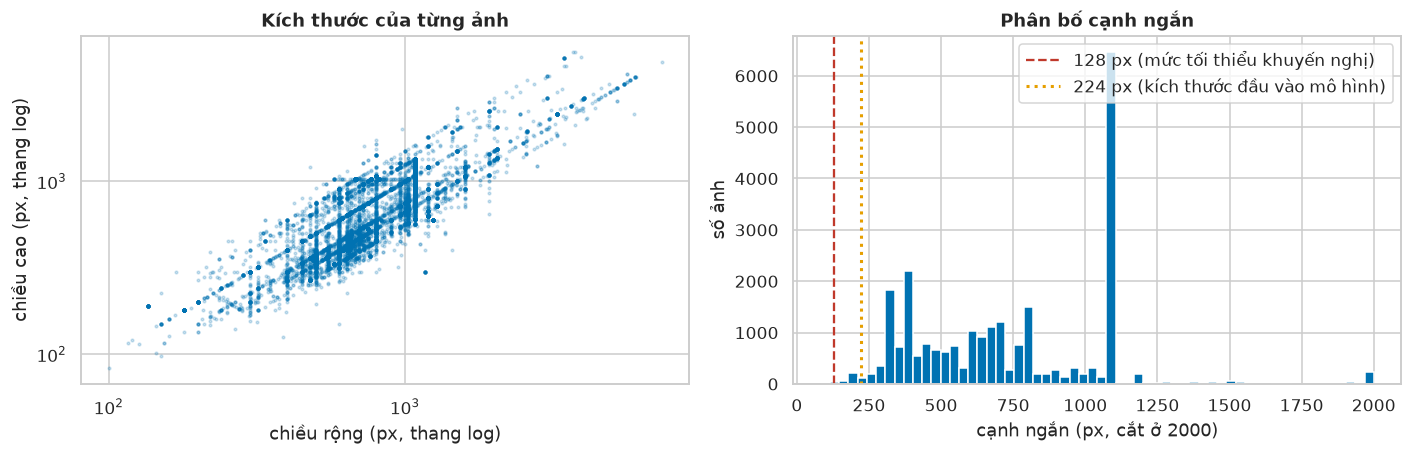

**Hình 1.** Kích thước ảnh rất đa dạng: cạnh ngắn trung vị 700 px, từ 83 đến 4912 px. Chỉ **9 ảnh** (0.04%) có cạnh ngắn dưới 128 px và 347 ảnh (1.4%) dưới 224 px. Kết luận: độ phân giải không phải vấn đề lớn của bộ dữ liệu này.

,path,split,folder,width,height
0,train/Banh bot loc/160.jpg,train,Banh bot loc,120,120
1,train/Banh chung/228.jpg,train,Banh chung,100,83
2,train/Banh duc/424.jpg,train,Banh duc,150,98
3,train/Bun bo Hue/1510.jpg,train,Bun bo Hue,116,116
4,train/Goi cuon/57.jpg,train,Goi cuon,145,101
5,val/Com tam/681.jpg,val,Com tam,387,125
6,test/Banh chung/82.jpg,test,Banh chung,127,114
7,test/Ca kho to/383.jpg,test,Ca kho to,154,116
8,test/Ca kho to/406.jpg,test,Ca kho to,154,116


In [10]:
ok = ~df["corrupt"]
display(df[ok].groupby("split", observed=True)["short_side"].describe().round(0))

d = df[ok]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].scatter(d["width"], d["height"], s=3, alpha=0.2, color="#0072B2")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("chiều rộng (px, thang log)"); axes[0].set_ylabel("chiều cao (px, thang log)")
axes[0].set_title("Kích thước của từng ảnh")
axes[1].hist(d["short_side"].clip(upper=2000), bins=60, color="#0072B2")
axes[1].axvline(128, color="#c0392b", ls="--", label="128 px (mức tối thiểu khuyến nghị)")
axes[1].axvline(224, color="#E69F00", ls=":", lw=2, label="224 px (kích thước đầu vào mô hình)")
axes[1].set_xlabel("cạnh ngắn (px, cắt ở 2000)"); axes[1].set_ylabel("số ảnh"); axes[1].legend()
axes[1].set_title("Phân bố cạnh ngắn")
fig.tight_layout()

n128, n224 = int((d["short_side"] < 128).sum()), int((d["short_side"] < 224).sum())
show_fig(fig, "fig01_image_sizes",
    f"Kích thước ảnh rất đa dạng: cạnh ngắn trung vị {d['short_side'].median():.0f} px, từ {d['short_side'].min()} đến "
    f"{d['short_side'].max()} px. Chỉ **{n128} ảnh** ({pct(n128 / len(d), 2)}) có cạnh ngắn dưới 128 px và {n224} ảnh "
    f"({pct(n224 / len(d))}) dưới 224 px. Kết luận: độ phân giải không phải vấn đề lớn của bộ dữ liệu này.")

small = df[ok & (df["short_side"] < 128)]
display(small[["path", "split", "folder", "width", "height"]].reset_index(drop=True))

- **Nhận xét:**
  - Cạnh ngắn trung vị là 700 px ở cả ba tập, phần lớn ảnh lớn hơn nhiều so với 224 px mà mô hình cần.
  - Chỉ 9 ảnh (0.04%) có cạnh ngắn dưới 128 px: 5 ảnh ở train, 1 ở validation và 3 ở test; nhỏ nhất là 100 x 83 px.
  - 347 ảnh (1.4%) có cạnh ngắn dưới 224 px và sẽ được phóng to nhẹ.
- **Quyết định:** bỏ 5 ảnh nhỏ khỏi train (mục 5.1); giữ 4 ảnh nhỏ ở validation và test để không thay đổi tập đánh giá chính thức, và phóng to chúng lên 224 x 224 như mọi ảnh khác (mục 5.3).

### 3.3 Ảnh trùng lặp

Ảnh lấy từ Internet thường bị trùng: cùng một ảnh được tải về nhiều lần, có khi đã bị nén lại, thu nhỏ hoặc cắt nhẹ.
So sánh từng byte không tìm được những bản như vậy, nên notebook dùng **mã băm cảm nhận** (pHash): mỗi ảnh được tóm tắt
thành 64 bit mô tả cấu trúc tổng thể của ảnh, và hai bản của cùng một ảnh có mã băm giống hoặc gần giống nhau.

- **Trùng hoàn toàn:** hai mã băm giống hệt nhau (khoảng cách Hamming bằng 0).
- **Gần trùng:** hai mã băm khác nhau 1-6 bit trên 64 bit.

Mọi cặp ảnh đều được so sánh (khoảng 316 triệu cặp) bằng phép XOR và đếm bit của numpy, theo từng khối dòng. Ảnh trùng
gây hai vấn đề: một ảnh có bản sao vừa ở train vừa ở test làm điểm test cao hơn thực tế (**rò rỉ dữ liệu**, xử lý
ở mục 5.1), và hai bản của cùng một ảnh mang **hai nhãn khác nhau** là nhãn nhiễu.

In [11]:
def popcount64(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    table = np.array([bin(i).count("1") for i in range(256)], np.uint8)
    return table[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)

def near_duplicate_pairs(h, max_dist=6, chunk=1024):
    I, J, D = [], [], []
    for start in range(0, len(h), chunk):
        dist = popcount64(h[start:start + chunk, None] ^ h[None, :])
        i, j = np.nonzero(dist <= max_dist)
        keep = j > i + start
        I.append(i[keep] + start); J.append(j[keep]); D.append(dist[i[keep], j[keep]])
    return np.concatenate(I), np.concatenate(J), np.concatenate(D)

valid = np.flatnonzero(ok.values)
PHASH = np.array([int(h, 16) for h in df.loc[valid, "phash"]], dtype=np.uint64)
pi, pj, dist = near_duplicate_pairs(PHASH)
pairs = pd.DataFrame({"i": valid[pi], "j": valid[pj], "dist": dist.astype(int)})
split_of = df["split"].astype(str).values
pairs["cross_class"] = df["folder"].values[pairs["i"]] != df["folder"].values[pairs["j"]]
pairs["kind"] = np.where(pairs["dist"] == 0, "exact", "near")
order = {s: k for k, s in enumerate(SPLITS)}
pairs["splits"] = [" - ".join(sorted((split_of[a], split_of[b]), key=order.get)) for a, b in zip(pairs["i"], pairs["j"])]
print(f"So cap da so sanh: {len(valid) * (len(valid) - 1) // 2:,}; so cap trung: {len(pairs):,}")

dup_table = pairs.pivot_table(index="splits", columns="kind", values="i", aggfunc="count", fill_value=0)
dup_table["cross_class"] = pairs.groupby("splits")["cross_class"].sum()
dup_table = dup_table.reindex([s for s in ["train - train", "val - val", "test - test", "train - val",
                                           "train - test", "val - test"] if s in dup_table.index])
dup_table.loc["total"] = dup_table.sum()
display(dup_table)
n_dup_images = len(set(pairs["i"]) | set(pairs["j"]))
print(f"So anh nam trong it nhat mot cap trung: {n_dup_images:,} ({n_dup_images / ok.sum():.1%})")

So cap da so sanh: 315,896,680; so cap trung: 403


kind,exact,near,cross_class
splits,,,
train - train,96,78,21
val - val,4,0,0
test - test,11,12,6
train - val,35,23,10
train - test,84,44,25
val - test,9,7,3
total,239,164,65


So anh nam trong it nhat mot cap trung: 757 (3.0%)


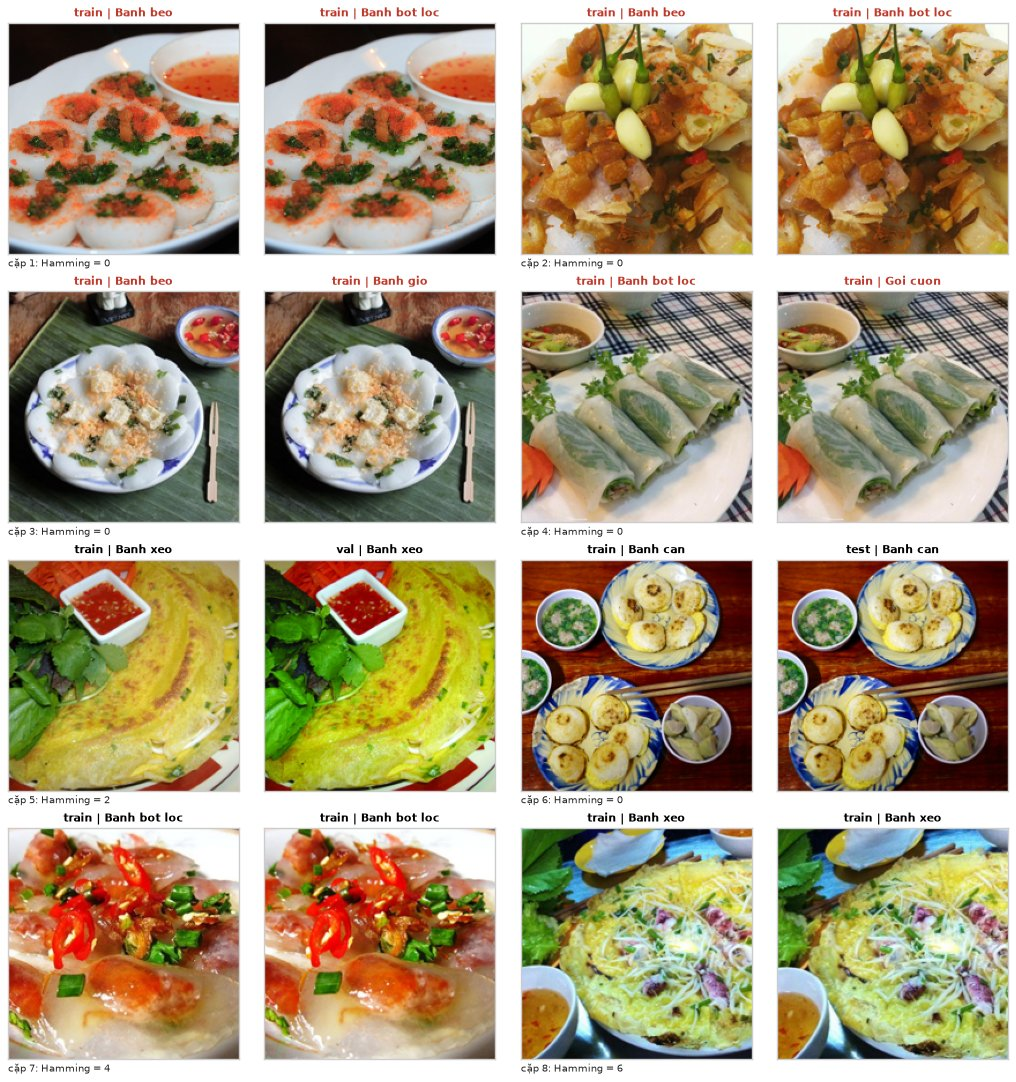

**Hình 2.** Ví dụ các cặp ảnh trùng do pHash tìm được (tên màu đỏ: hai bản mang nhãn khác nhau). 4 cặp đầu là cùng một ảnh nhưng được xếp vào **hai món khác nhau**, ví dụ Banh beo và Banh bot loc: dù giữ nhãn nào thì một bản vẫn sai. Hai cặp tiếp theo là ảnh có bản sao ở cả train lẫn validation hoặc test, hai cặp cuối là ảnh gần trùng (nén lại hoặc cắt nhẹ) trong train. Kết luận: 403 cặp trùng, trong đó 65 cặp khác nhãn, cần được xử lý trước khi huấn luyện.

In [12]:
def show_pairs(sel, name, caption):
    ncols = 2
    rows = int(np.ceil(len(sel) / ncols))
    fig, axes = plt.subplots(rows, 2 * ncols, figsize=(13, 3.4 * rows))
    axes = np.atleast_2d(axes)
    for k, (_, r) in enumerate(sel.iterrows()):
        for m, idx in enumerate((r["i"], r["j"])):
            ax = axes[k // ncols, 2 * (k % ncols) + m]
            ax.imshow(load_rgb(df.at[idx, "path"], 200)); ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{split_of[idx]} | {df.at[idx, 'folder']}", fontsize=10,
                         color="#c0392b" if r["cross_class"] else "black")
            if m == 0:
                ax.set_xlabel(f"cặp {k + 1}: Hamming = {r['dist']}", fontsize=9, loc="left")
    for ax in axes.ravel()[2 * len(sel):]:
        ax.axis("off")
    fig.tight_layout()
    show_fig(fig, name, caption, photo=True)

pick_cc = pairs[pairs["cross_class"]].sort_values(["dist", "i"]).head(4)
pick_split = pairs[~pairs["cross_class"] & pairs["splits"].isin(["train - val", "train - test"])]
pick_split = pick_split.sample(min(2, len(pick_split)), random_state=SEED)
pick_near = pairs[~pairs["cross_class"] & (pairs["splits"] == "train - train") & (pairs["dist"] > 0)]
pick_near = pick_near.sample(min(2, len(pick_near)), random_state=SEED)
show_pairs(pd.concat([pick_cc, pick_split, pick_near]), "fig02_duplicate_pairs",
    f"Ví dụ các cặp ảnh trùng do pHash tìm được (tên màu đỏ: hai bản mang nhãn khác nhau). {len(pick_cc)} cặp đầu là cùng "
    f"một ảnh nhưng được xếp vào **hai món khác nhau**, ví dụ {df.at[pick_cc['i'].iloc[0], 'folder']} và "
    f"{df.at[pick_cc['j'].iloc[0], 'folder']}: dù giữ nhãn nào thì một bản vẫn sai. Hai cặp tiếp theo là ảnh có bản sao ở cả "
    f"train lẫn validation hoặc test, hai cặp cuối là ảnh gần trùng (nén lại hoặc cắt nhẹ) trong train. Kết luận: "
    f"{len(pairs):,} cặp trùng, trong đó {int(pairs['cross_class'].sum())} cặp khác nhãn, cần được xử lý trước khi huấn luyện.")

- **Nhận xét:**
  - Có 403 cặp ảnh trùng (239 cặp trùng hoàn toàn, 164 cặp gần trùng), liên quan đến 757 ảnh (3.0% bộ dữ liệu).
  - Nhãn mâu thuẫn: 65 cặp mang hai nhãn khác nhau, ví dụ cùng một ảnh vừa là bánh bèo vừa là bánh bột lọc, hay vừa là bánh bột lọc vừa là gỏi cuốn (Hình 2).
  - Rò rỉ: 128 cặp nối train với test và 58 cặp nối train với validation.
  - Bên trong validation và test cũng có 4 và 23 cặp trùng.
- **Quyết định:**
  - Bỏ bản ở train của mọi cặp nối train với validation hoặc test.
  - Bỏ cả hai bản của cặp khác nhãn trong train; với nhóm ảnh trùng cùng nhãn trong train, giữ một bản.
  - Giữ nguyên validation và test để so sánh được với bài báo, chỉ đánh dấu ảnh trùng (mục 5.1).

### 3.4 Tổng kết: vấn đề và cách xử lý

| Vấn đề | Kết quả kiểm tra | Cách xử lý | Mục |
|---|---|---|---|
| File lỗi | 0 | nếu có thì bỏ khỏi train/val/test | 5.1 |
| Định dạng khác JPEG | 129 file (PNG, MPO, BMP) | giữ lại, PIL đọc theo nội dung file | 3.1 |
| Chế độ màu khác RGB | 0 | vẫn đổi sang RGB, cần cho ảnh mới | 5.3, 8 |
| Ảnh có cạnh ngắn < 128 px | 9 ảnh (5 ở train) | bỏ khỏi train; giữ ở val/test và phóng to | 5.1, 5.3 |
| Kích thước khác nhau | cạnh ngắn từ 83 đến 4 912 px | đưa về 224 x 224 | 5.3 |
| Ảnh trùng giữa train và val/test | 186 cặp | bỏ khỏi train | 5.1 |
| Ảnh trùng mang nhãn khác | 65 cặp | bỏ khỏi train; đánh dấu ở val/test | 5.1, 7.4 |
| Ảnh trùng cùng nhãn trong train | 153 cặp | giữ một bản cho mỗi nhóm, bỏ các bản còn lại khỏi train | 5.1 |
| Lớp mất cân bằng | món nhiều ảnh nhất gấp 3.5 lần món ít nhất (mục 4.1) | chọn mô hình theo macro-F1 | 6.1 |

## 4. Phân tích khám phá (EDA)
Phân tích khám phá chỉ dùng **tập train** (riêng Hình 3 so sánh ba tập), để mọi hiểu biết về dữ liệu không đến từ
tập test.

### 4.1 Các lớp có cân bằng không?
Nếu một vài món có ít ảnh hơn hẳn, accuracy có thể che mất việc các món đó bị nhận sai.

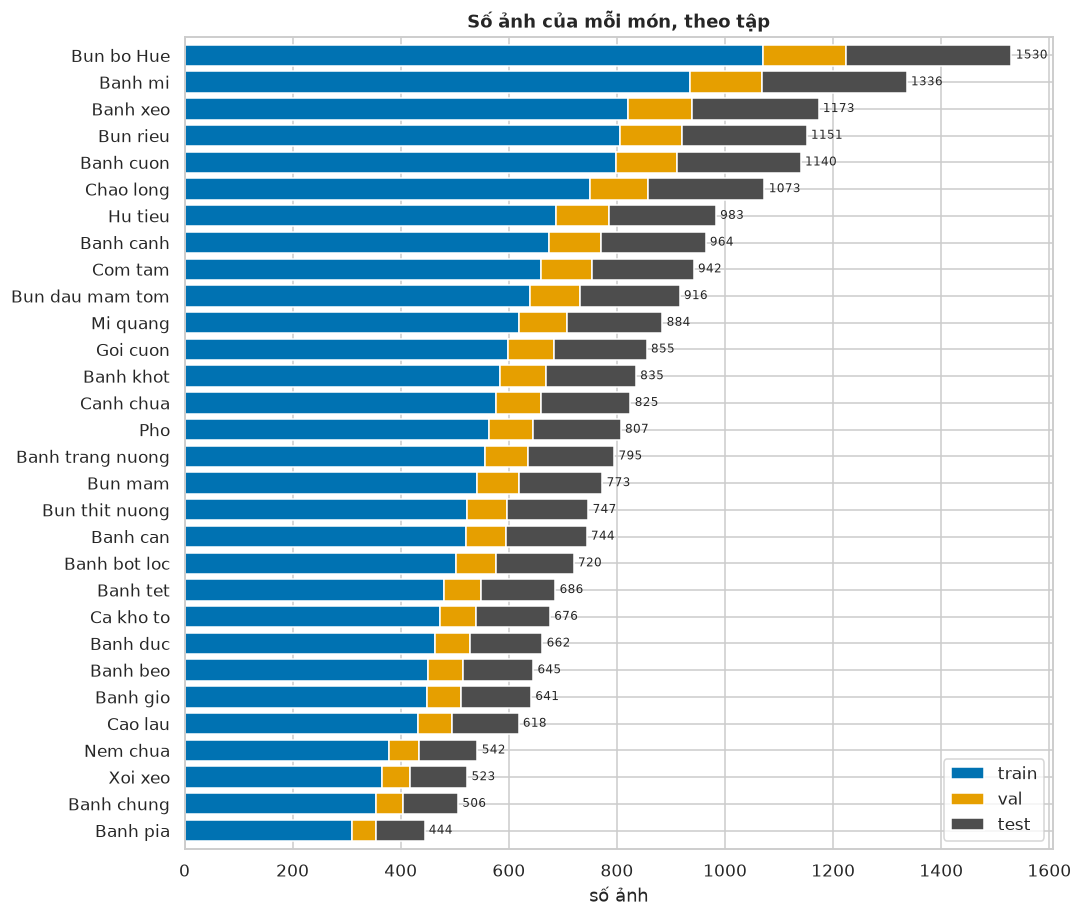

**Hình 3.** Món nhiều ảnh nhất trong train (**Bun bo Hue**, 1071 ảnh) gấp 3.5 lần món ít ảnh nhất (**Banh pia**, 310 ảnh); trung vị 560 ảnh mỗi món. Ba tập giữ cùng tỉ lệ giữa các món (train 70%, val 10%, test 20%). Kết luận: mất cân bằng ở mức vừa phải; vẫn dùng **macro-F1** để mọi món có trọng số như nhau.

In [13]:
cnt = df[ok].pivot_table(index="folder", columns="split", values="path", aggfunc="count", observed=True)[SPLITS]
cnt = cnt.loc[cnt["train"].sort_values().index]
fig, ax = plt.subplots(figsize=(10, 8.5))
left = np.zeros(len(cnt))
for split in SPLITS:
    ax.barh(cnt.index, cnt[split], left=left, color=SPLIT_COLORS[split], label=split)
    left += cnt[split].values
for yy, v in enumerate(left):
    ax.text(v + 8, yy, f"{int(v)}", va="center", fontsize=8)
ax.set_xlabel("số ảnh"); ax.set_ylabel(""); ax.legend(loc="lower right"); ax.margins(y=0.01)
ax.set_title("Số ảnh của mỗi món, theo tập")
fig.tight_layout()

tr_cnt = cnt["train"]
split_share = cnt.sum() / cnt.values.sum()
show_fig(fig, "fig03_class_counts",
    f"Món nhiều ảnh nhất trong train (**{tr_cnt.index[-1]}**, {tr_cnt.iloc[-1]} ảnh) gấp {tr_cnt.iloc[-1] / tr_cnt.iloc[0]:.1f} "
    f"lần món ít ảnh nhất (**{tr_cnt.index[0]}**, {tr_cnt.iloc[0]} ảnh); trung vị {tr_cnt.median():.0f} ảnh mỗi món. Ba tập "
    f"giữ cùng tỉ lệ giữa các món (train {pct(split_share['train'], 0)}, val {pct(split_share['val'], 0)}, "
    f"test {pct(split_share['test'], 0)}). Kết luận: mất cân bằng ở mức vừa phải; vẫn dùng **macro-F1** để mọi món có "
    f"trọng số như nhau.")

- **Nhận xét:**
  - Bún bò Huế có nhiều ảnh train nhất (1 071 ảnh), Bánh pía ít nhất (310 ảnh), chênh 3.5 lần; trung vị 560 ảnh mỗi món.
  - Món ít ảnh nhất vẫn có hơn 300 ảnh train.
  - Ba tập có cùng tỉ lệ giữa các món, nên cách chia chính thức là đại diện.
- **Quyết định:** giữ mọi món, không lấy mẫu lại và không dùng trọng số lớp; chọn mô hình theo macro-F1 (mục 6.1).

### 4.2 Các món trông như thế nào?
Bốn ảnh ngẫu nhiên của mỗi món trong tập train cho thấy độ khó của bài toán trước khi xây dựng mô hình.

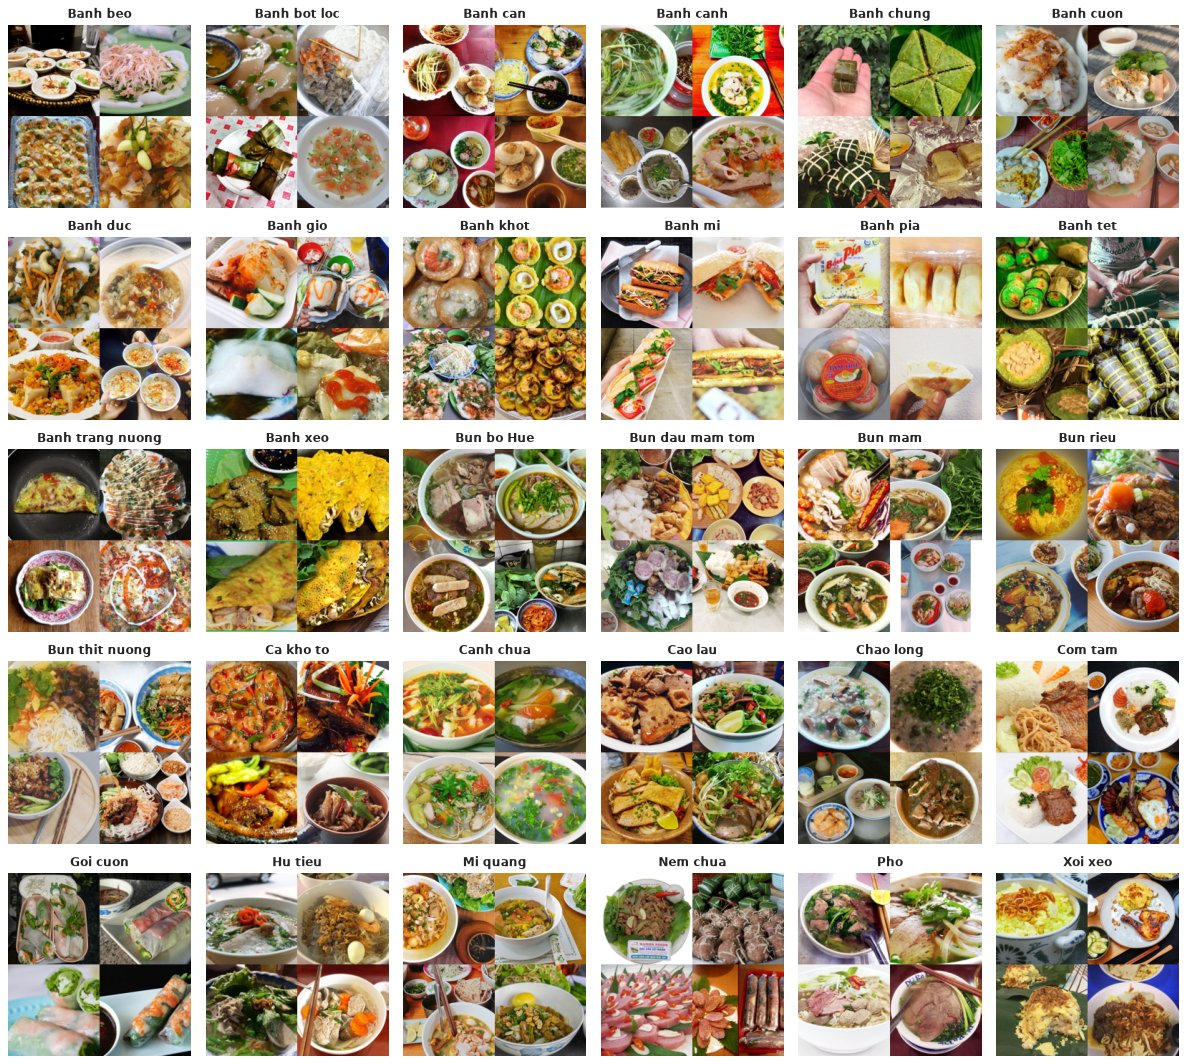

**Hình 4.** Bốn ảnh train ngẫu nhiên của mỗi món. Ảnh được chụp từ nhiều góc, nhiều kiểu bày đĩa và điều kiện ánh sáng khác nhau, có ảnh chèn chữ hoặc có nhiều món trong một khung hình. Kết luận: nhiều món rất giống nhau, ví dụ các món nước (phở, bún bò Huế, hủ tiếu, bún riêu, bánh canh) hay các loại bánh làm từ bột gạo (bánh bèo, bánh đúc, bánh bột lọc), nên đây là những chỗ mô hình dễ nhầm.

In [14]:
rng = np.random.default_rng(SEED)
train_ok = df[ok & (df["split"] == "train")]
fig, axes = plt.subplots(5, 6, figsize=(15, 13.5))
for ax, folder in zip(axes.ravel(), sorted(train_ok["folder"].unique())):
    paths = rng.choice(train_ok.loc[train_ok["folder"] == folder, "path"].values, size=4, replace=False)
    tiles = [load_rgb(p, 128) for p in paths]
    ax.imshow(np.vstack([np.hstack(tiles[:2]), np.hstack(tiles[2:])]))
    ax.set_title(folder, fontsize=11); ax.axis("off")
fig.tight_layout()
show_fig(fig, "fig04_sample_grid",
    "Bốn ảnh train ngẫu nhiên của mỗi món. Ảnh được chụp từ nhiều góc, nhiều kiểu bày đĩa và điều kiện ánh sáng khác "
    "nhau, có ảnh chèn chữ hoặc có nhiều món trong một khung hình. Kết luận: nhiều món rất giống nhau, ví dụ các món nước "
    "(phở, bún bò Huế, hủ tiếu, bún riêu, bánh canh) hay các loại bánh làm từ bột gạo (bánh bèo, bánh đúc, bánh bột lọc), "
    "nên đây là những chỗ mô hình dễ nhầm.", photo=True)

### 4.3 Màu sắc có đủ để phân biệt các món không?
Mỗi ảnh được tóm tắt bằng độ bão hòa màu và độ sáng trung bình (mục 3.1). Nếu các món khác nhau rõ về hai số này thì
đặc trưng màu sắc đơn giản đã đủ để phân loại.

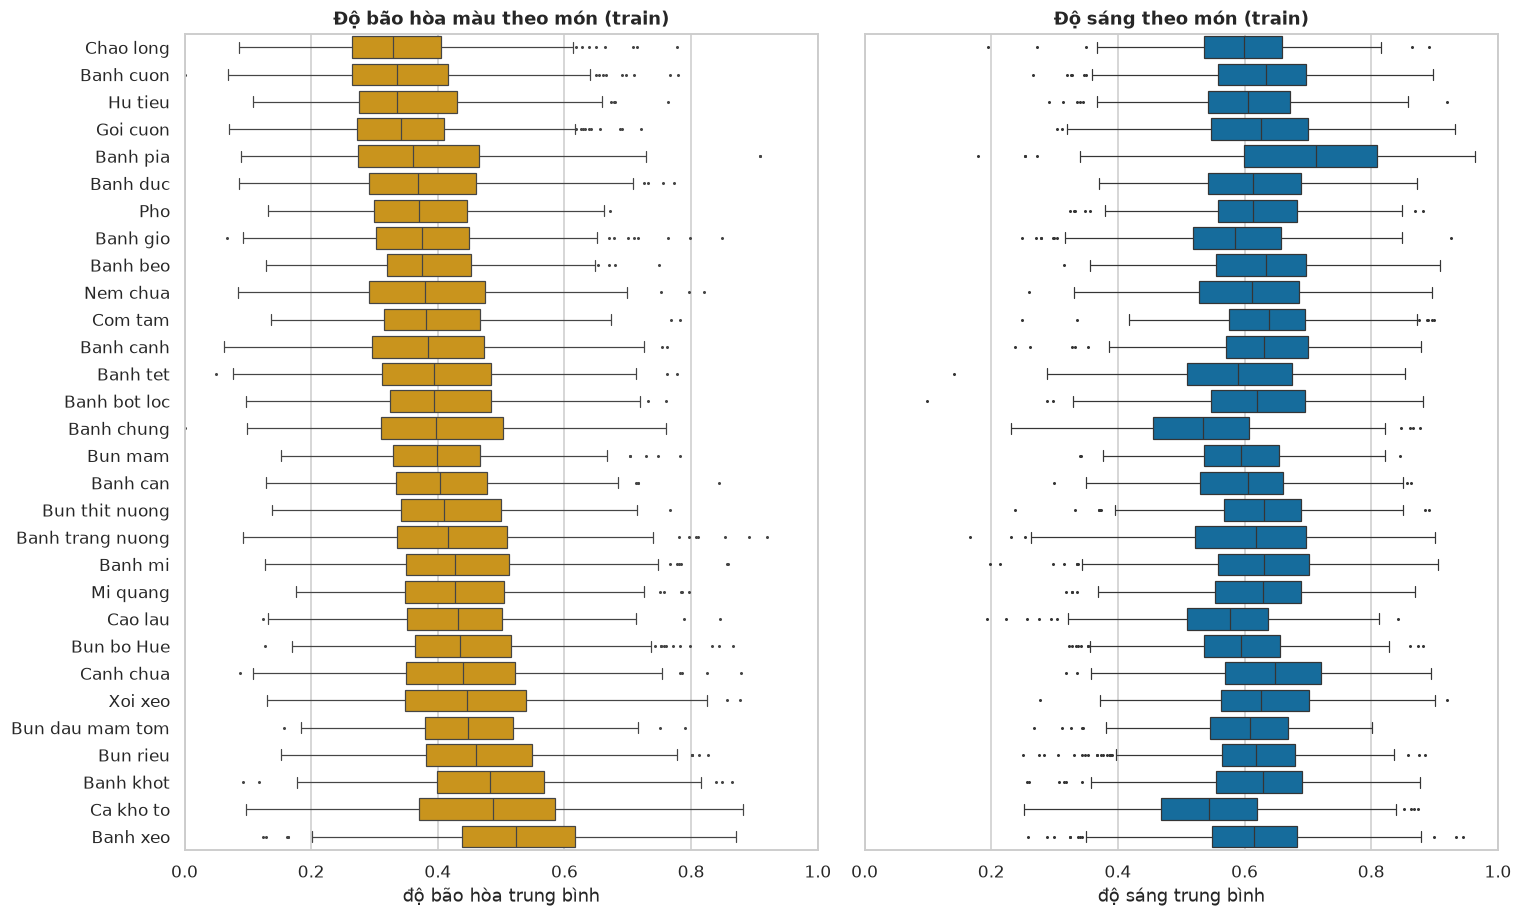

**Hình 5.** Trung vị độ bão hòa của các món chỉ trải từ 0.33 (*Chao long*) đến 0.52 (*Banh xeo*), trong khi khoảng tứ phân vị bên trong một món trung bình đã rộng 0.16. Độ sáng cũng chồng lấn tương tự. Kết luận: màu sắc tổng thể có mang thông tin (độ bão hòa cao nhất ở Banh xeo, Ca kho to, Banh khot, thấp nhất ở Chao long, Banh cuon, Hu tieu) nhưng các món chồng lấn rất nhiều, nên đặc trưng màu sắc đơn giản khó đủ để phân biệt 30 món.

In [15]:
tr = df[ok & (df["split"] == "train")]
order_sat = tr.groupby("folder")["saturation"].median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 8.5), sharey=True)
for ax, col, name, color in [(axes[0], "saturation", "độ bão hòa trung bình", "#E69F00"),
                             (axes[1], "brightness", "độ sáng trung bình", "#0072B2")]:
    sns.boxplot(data=tr, y="folder", x=col, order=order_sat, ax=ax, color=color, fliersize=1, linewidth=0.8)
    ax.set_xlabel(name); ax.set_ylabel(""); ax.set_xlim(0, 1)
axes[0].set_title("Độ bão hòa màu theo món (train)"); axes[1].set_title("Độ sáng theo món (train)")
fig.tight_layout()

med_sat = tr.groupby("folder")["saturation"].median()
iqr_sat = tr.groupby("folder")["saturation"].quantile(0.75) - tr.groupby("folder")["saturation"].quantile(0.25)
show_fig(fig, "fig05_colour_stats",
    f"Trung vị độ bão hòa của các món chỉ trải từ {med_sat.min():.2f} (*{med_sat.idxmin()}*) đến {med_sat.max():.2f} "
    f"(*{med_sat.idxmax()}*), trong khi khoảng tứ phân vị bên trong một món trung bình đã rộng {iqr_sat.mean():.2f}. "
    f"Độ sáng cũng chồng lấn tương tự. Kết luận: màu sắc tổng thể có mang thông tin (độ bão hòa cao nhất ở "
    f"{', '.join(med_sat.nlargest(3).index)}, thấp nhất ở {', '.join(med_sat.nsmallest(3).index)}) nhưng các món chồng "
    f"lấn rất nhiều, nên đặc trưng màu sắc đơn giản khó đủ để phân biệt 30 món.")

### 4.4 Tổng kết EDA

- **Số ảnh mỗi món:** từ 310 đến 1 071 ảnh train (chênh 3.5 lần), mất cân bằng ở mức vừa phải. Mô hình được chọn theo
  macro-F1.
- **Nội dung ảnh:** ảnh chụp thực tế với góc chụp, cách bày và ánh sáng rất khác nhau; nhiều món cùng kiểu (món nước,
  bánh làm từ bột gạo) trông giống nhau.
- **Màu sắc:** độ bão hòa và độ sáng của các món chồng lấn nhiều, nên chỉ dùng màu sắc thì khó phân biệt. Cần đặc trưng
  mô tả được hình dạng và chi tiết của món ăn, như đặc trưng của một mạng CNN đã huấn luyện sẵn.
- **Kích thước:** cạnh ngắn trung vị 700 px, đủ lớn để đưa về 224 x 224 mà không mất chi tiết.

## 5. Tiền xử lý dữ liệu
Các bước được áp dụng theo thứ tự sau:

| Mục | Bước | Áp dụng cho |
|---|---|---|
| 5.1 | Bỏ ảnh lỗi; bỏ ảnh nhỏ và ảnh trùng khỏi train | ảnh lỗi: train/val/test; ảnh nhỏ, ảnh trùng: train |
| 5.2 | Mã hóa nhãn | train/val/test (fit trên train) |
| 5.3 | Thu nhỏ ảnh, lưu vào `data/processed/`, chuẩn hóa | train/val/test |
| 5.4 | Tăng cường dữ liệu | train (chỉ khi fine-tune) |
| 5.5 | Kích thước cuối cùng của ba tập | |

**Nguyên tắc chống rò rỉ dữ liệu:** validation và test không bị bỏ ảnh nào (trừ file lỗi), để giữ nguyên cách chia
chính thức và so sánh được với bài báo gốc. Mọi thống kê học từ dữ liệu (bộ mã hóa nhãn, `StandardScaler`) chỉ fit
trên train.

### 5.1 Bỏ ảnh lỗi, ảnh nhỏ và ảnh trùng khỏi train

| Quy tắc | Áp dụng cho | Cách xử lý | Lý do |
|---|---|---|---|
| File lỗi | train/val/test | bỏ | không đọc được |
| Cạnh ngắn < 128 px | train | bỏ khỏi train | quá ít chi tiết; ảnh nhỏ ở val/test vẫn giữ và được phóng to (mục 5.3) |
| Trùng với một ảnh val/test | train | bỏ khỏi train | tránh rò rỉ: mô hình không được thấy trước ảnh test |
| Cặp trùng khác nhãn trong train | train | bỏ cả hai bản khỏi train | không biết nhãn nào đúng |
| Cặp trùng cùng nhãn trong train | train | giữ một bản cho mỗi nhóm, bỏ các bản còn lại khỏi train | ảnh lặp lại làm vài mẫu có trọng số quá lớn |
| Ảnh trùng bên trong val/test | val/test | giữ, chỉ đánh dấu | giữ nguyên tập đánh giá chính thức |

Ảnh val/test được đánh dấu bằng hai cột: `dup_in_train` (có bản gần trùng trong train *trước khi* làm sạch; bản ở
train đã bị bỏ) và `cross_class_dup` (có bản sao mang nhãn khác, dùng ở mục 7.4).

In [16]:
is_train = (df["split"] == "train").values
reason = np.where(df["corrupt"], "corrupt", "").astype(object)
reason[(reason == "") & is_train & (df["short_side"] < 128).values] = "small"

i, j = pairs["i"].values, pairs["j"].values
tr_i, tr_j = is_train[i], is_train[j]
cc = pairs["cross_class"].values

df["dup_in_train"] = False
df.loc[np.r_[i[~tr_i & tr_j], j[tr_i & ~tr_j]], "dup_in_train"] = True
df["cross_class_dup"] = False
df.loc[np.r_[i[cc], j[cc]], "cross_class_dup"] = True

leak = np.zeros(len(df), bool)
leak[np.r_[i[tr_i & ~tr_j], j[tr_j & ~tr_i]]] = True
reason[(reason == "") & leak] = "dup_of_val_test"
conflict = np.zeros(len(df), bool)
conflict[np.r_[i[tr_i & tr_j & cc], j[tr_i & tr_j & cc]]] = True
reason[(reason == "") & conflict] = "dup_other_label"

parent = {}
def find(x):
    while parent.setdefault(x, x) != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in zip(i[tr_i & tr_j & ~cc], j[tr_i & tr_j & ~cc]):
    if reason[a] == "" and reason[b] == "":
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
for x in list(parent):
    if find(x) != x:
        reason[x] = "dup_same_label"

df["drop_reason"] = reason
df["keep"] = df["drop_reason"] == ""
by_split = df.groupby("split", observed=True)
DATA_SUMMARY = pd.DataFrame({
    "raw": by_split.size(),
    "corrupt": by_split["drop_reason"].apply(lambda s: s.eq("corrupt").sum()),
    "small": by_split["drop_reason"].apply(lambda s: s.eq("small").sum()),
    "duplicate": by_split["drop_reason"].apply(lambda s: s.str.startswith("dup").sum()),
    "final": by_split["keep"].sum(),
})
DATA_SUMMARY.index = DATA_SUMMARY.index.astype(str)
DATA_SUMMARY.loc["total"] = DATA_SUMMARY.sum()
display(DATA_SUMMARY)
print("Ly do bo anh:", df.loc[df["drop_reason"] != "", "drop_reason"].value_counts().to_dict())
te = df["split"] == "test"
print(f"Anh test co ban gan trung trong train truoc khi lam sach: {df.loc[te, 'dup_in_train'].sum()} "
      f"({df.loc[te, 'dup_in_train'].mean():.1%})")
print(f"Anh test co ban sao mang nhan khac: {df.loc[te, 'cross_class_dup'].sum()}")

,raw,corrupt,small,duplicate,final
split,,,,,
train,17581,0,5,361,17215
val,2515,0,0,0,2515
test,5040,0,0,0,5040
total,25136,0,5,361,24770


Ly do bo anh: {'dup_of_val_test': 182, 'dup_same_label': 144, 'dup_other_label': 35, 'small': 5}
Anh test co ban gan trung trong train truoc khi lam sach: 123 (2.4%)
Anh test co ban sao mang nhan khac: 37


- **Nhận xét:**
  - Train giảm từ 17 581 xuống 17 215 ảnh (bỏ 366 ảnh, 2.1%): 182 ảnh trùng với val/test, 144 ảnh lặp lại cùng nhãn, 35 ảnh trùng khác nhãn và 5 ảnh nhỏ.
  - Validation và test giữ nguyên 2 515 và 5 040 ảnh.
  - 123 ảnh test (2.4%) có bản gần trùng trong train trước khi làm sạch (các bản ở train đã bị bỏ, nên mô hình không thấy trước những ảnh test này), và 37 ảnh test có bản sao mang nhãn khác (dùng ở mục 7.4).

### 5.2 Mã hóa nhãn
`LabelEncoder` đổi tên thư mục sang số nguyên 0-29 theo thứ tự bảng chữ cái. Bộ mã hóa được fit trên nhãn của train
và dùng chung cho mọi mô hình; `DISH[k]` là tên món (tên thư mục) của mã `k`.

In [17]:
le = LabelEncoder().fit(df.loc[df["split"] == "train", "folder"])
df["label"] = le.transform(df["folder"])
DISH = list(le.classes_)
N_CLASSES = len(le.classes_)
codes = pd.DataFrame({"code": range(N_CLASSES), "folder": DISH})
display(pd.concat([codes.iloc[k * 10:(k + 1) * 10].reset_index(drop=True) for k in range(3)], axis=1))

,code,folder,code,folder,code,folder
0,0,Banh beo,10,Banh pia,20,Canh chua
1,1,Banh bot loc,11,Banh tet,21,Cao lau
2,2,Banh can,12,Banh trang nuong,22,Chao long
3,3,Banh canh,13,Banh xeo,23,Com tam
4,4,Banh chung,14,Bun bo Hue,24,Goi cuon
5,5,Banh cuon,15,Bun dau mam tom,25,Hu tieu
6,6,Banh duc,16,Bun mam,26,Mi quang
7,7,Banh gio,17,Bun rieu,27,Nem chua
8,8,Banh khot,18,Bun thit nuong,28,Pho
9,9,Banh mi,19,Ca kho to,29,Xoi xeo


### 5.3 Đưa ảnh về cùng kích thước và chuẩn hóa
Mạng ResNet50 (mục 6) nhận ảnh 224 x 224 px, trong khi ảnh gốc có cạnh ngắn trung vị 700 px và lớn nhất gần 5 000 px
(mục 3.2). Giải mã một ảnh JPEG lớn tốn nhiều thời gian hơn hẳn một ảnh nhỏ, và mỗi ảnh train được đọc lại ở mọi epoch
khi fine-tune. Vì vậy ảnh được xử lý theo hai bước:

1. **Thu nhỏ một lần và lưu lại.** Mọi ảnh không bị lỗi được thu nhỏ để cạnh ngắn bằng 256 px (giữ nguyên tỉ lệ, xoay đúng
   chiều theo EXIF, đổi sang RGB) và lưu vào `data/processed/`, cùng cấu trúc thư mục với `data/`. Ảnh vốn nhỏ hơn 256 px
   được giữ nguyên kích thước. Mọi mô hình ở mục 6 đọc ảnh từ thư mục này; ảnh gốc không bị thay đổi. Chọn 256 px vì
   đó là kích thước trước bước cắt 224 x 224 bên dưới, nên không mất thông tin mà mô hình sẽ dùng.
2. **Biến đổi khi đưa vào mạng.** Đổi kích thước để cạnh ngắn bằng 256 px, cắt lấy phần giữa 224 x 224 px (không bóp méo
   món ăn), đổi sang tensor có giá trị 0-1 và chuẩn hóa từng kênh màu theo trung bình và độ lệch chuẩn của ImageNet,
   tương đương bước *scaling* của dữ liệu số. Ảnh nhỏ hơn 256 px, kể cả các ảnh dưới 128 px còn lại ở validation và
   test, được phóng to ở bước này; không cần thêm viền (padding) vì ảnh luôn được cắt thành hình vuông.

Với Logistic Regression ở mục 6, vector đặc trưng của mỗi ảnh còn được chuẩn hóa thêm, bên trong `Pipeline`:

- **Đặc trưng ResNet50:** chuẩn hóa L2 (`Normalizer`), đưa mỗi vector về độ dài 1, giống cách TF-IDF chuẩn hóa vector
  câu. Mọi chiều đều là đầu ra của cùng một mạng nên đã cùng thang đo; chỉ cần bỏ khác biệt về độ lớn giữa các ảnh.
- **Đặc trưng thủ công:** `StandardScaler` (fit trên train), vì histogram màu và histogram từ thị giác SIFT có thang đo khác nhau và cần đưa
  từng chiều về cùng thang.

In [18]:
PROC_SIDE = 256

def save_processed(path):
    out = PROC_DIR / path
    if out.exists():
        return
    with Image.open(DATA_DIR / path) as im:
        im.draft("RGB", (PROC_SIDE, PROC_SIDE))
        im = ImageOps.exif_transpose(im).convert("RGB")
    scale = PROC_SIDE / min(im.size)
    if scale < 1:
        im = im.resize((round(im.size[0] * scale), round(im.size[1] * scale)), Image.BILINEAR)
    out.parent.mkdir(parents=True, exist_ok=True)
    im.save(out, "JPEG", quality=90)

with ThreadPoolExecutor(max_workers=16) as pool:
    list(pool.map(save_processed, df.loc[ok, "path"]))
n_saved = sum(1 for p in PROC_DIR.glob("*/*/*") if p.is_file())
print(f"{PROC_DIR.relative_to(HERE)}/: {n_saved:,} anh")

data/processed/: 25,136 anh


In [19]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

x = eval_tf(Image.open(PROC_DIR / df.loc[df["keep"], "path"].iloc[0]).convert("RGB"))
print("Kich thuoc tensor:", tuple(x.shape))
print("Trung binh tung kenh sau chuan hoa:", x.mean(dim=(1, 2)).numpy().round(2))

Kich thuoc tensor: (3, 224, 224)
Trung binh tung kenh sau chuan hoa: [1.15 0.65 0.12]


### 5.4 Tăng cường dữ liệu
**Mục tiêu:** mỗi ảnh train được biến đổi ngẫu nhiên ở mỗi epoch, để mạng thấy nhiều phiên bản khác nhau của cùng một
ảnh, học những đặc điểm không đổi của món ăn thay vì học thuộc từng ảnh, và chịu được khác biệt khi người dùng chụp.

| Phép biến đổi | Tham số | Mục tiêu |
|---|---|---|
| `RandomResizedCrop` | 224 x 224, giữ 70-100% diện tích ảnh | mô phỏng khung hình và khoảng cách chụp khác nhau; giữ ít nhất 70% để món ăn vẫn nằm trong khung |
| `RandomHorizontalFlip` | xác suất 0.5 | ảnh lật ngang vẫn là cùng một món |
| `ColorJitter` | độ sáng và tương phản +-20%, độ bão hòa +-10%, sắc màu +-0.02 | mô phỏng ánh sáng khác nhau ở quán ăn; sắc màu chỉ đổi rất ít vì màu là đặc điểm thật của món (nước dùng đỏ của bún riêu, vỏ vàng của bánh xèo) |
| `Normalize` | trung bình và độ lệch chuẩn của ImageNet | không phải tăng cường, nhưng luôn áp dụng sau cùng (mục 5.3) |

Không lật dọc hay xoay mạnh, vì ảnh món ăn thật hiếm khi bị như vậy.

**Áp dụng cho:** chỉ tập train, và chỉ khi trọng số của mạng được huấn luyện (fine-tune, mục 6.3). Validation và test
luôn dùng phép biến đổi cố định ở mục 5.3, để điểm số không phụ thuộc vào phép biến đổi ngẫu nhiên. Ở cách trích đặc
trưng (mục 6.2), mạng không được huấn luyện nên mỗi ảnh chỉ đi qua mạng một lần với phép biến đổi cố định.

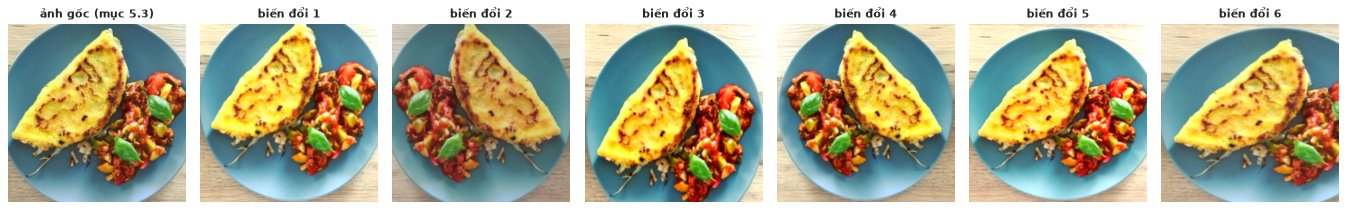

**Hình 6.** Một ảnh train của món Banh xeo và sáu phiên bản tăng cường ngẫu nhiên. Kết luận: cắt khung, lật ngang và thay đổi ánh sáng nhẹ tạo ra ảnh mới hợp lý, trong khi món ăn và màu sắc của nó vẫn nhận ra được.

In [20]:
augment = T.Compose([T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomHorizontalFlip(),
                     T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02)])
train_tf = T.Compose([augment, T.ToTensor(), T.Normalize(MEAN, STD)])

example = df[df["keep"] & (df["folder"] == "Banh xeo") & (df["split"] == "train")].iloc[3]
img = Image.open(PROC_DIR / example["path"]).convert("RGB")
torch.manual_seed(SEED)
views = [T.CenterCrop(224)(T.Resize(256)(img))] + [augment(img) for _ in range(6)]
fig, axes = plt.subplots(1, 7, figsize=(17, 2.9))
for k, (ax, v) in enumerate(zip(axes, views)):
    ax.imshow(v); ax.axis("off")
    ax.set_title("ảnh gốc (mục 5.3)" if k == 0 else f"biến đổi {k}", fontsize=10)
fig.tight_layout()
show_fig(fig, "fig06_augmentation",
    f"Một ảnh train của món {example['folder']} và sáu phiên bản tăng cường ngẫu nhiên. Kết luận: cắt khung, lật ngang và "
    f"thay đổi ánh sáng nhẹ tạo ra ảnh mới hợp lý, trong khi món ăn và màu sắc của nó vẫn nhận ra được.", photo=True)

### 5.5 Kích thước cuối cùng của ba tập
`n_images` là số ảnh dùng được, `share` là tỉ lệ so với tổng số, `min_per_class` và `max_per_class` là số ảnh của
món ít nhất và nhiều nhất trong tập đó.

In [21]:
kept = df[df["keep"]]
sizes = kept.groupby("split", observed=True).agg(n_images=("path", "size"))
sizes["share"] = (sizes["n_images"] / sizes["n_images"].sum()).map(pct)
per_class = kept.groupby(["split", "label"], observed=True).size()
sizes["min_per_class"] = per_class.groupby(level=0, observed=True).min()
sizes["max_per_class"] = per_class.groupby(level=0, observed=True).max()
display(sizes)

,n_images,share,min_per_class,max_per_class
split,,,,
train,17215,69.5%,306,1047
val,2515,10.2%,45,153
test,5040,20.3%,89,306


## 6. Xây dựng mô hình

**Hướng chính: học sâu với mạng đã huấn luyện sẵn.** Nhóm dùng **ResNet50** với trọng số `IMAGENET1K_V2` của
torchvision, đã huấn luyện trên ImageNet (1,2 triệu ảnh, 1 000 lớp), một trong các mạng đề gợi ý. Mạng được dùng như
một hàm có sẵn: nhận ảnh 224 x 224 và trả về một vector 2 048 chiều mô tả nội dung ảnh; lớp cuối của mạng biến vector
này thành xác suất của từng lớp. ResNet50 có sẵn trong torchvision và chạy nhanh trên GPU T4 của Colab; các mạng nhẹ
hơn như MobileNetV3 phù hợp hơn khi cần chạy trên điện thoại (mục 9.4).

Ba mô hình được xây dựng và so sánh:

| Mô hình | Mục | Đặc trưng của ảnh | Phần được huấn luyện | Đầu phân loại |
|---|---|---|---|---|
| ResNet50 trích đặc trưng | 6.2 | vector 2 048 chiều của ResNet50 giữ nguyên | chỉ đầu phân loại | Logistic Regression |
| ResNet50 fine-tune nhẹ | 6.3 | ResNet50, khối cuối `layer4` được học lại | `layer4` và đầu phân loại | lớp tuyến tính 2048 -> 30 + softmax |
| Baseline đặc trưng thủ công | 6.4 | histogram màu và SIFT (OpenCV) | chỉ đầu phân loại | Logistic Regression |

**Cùng một đầu phân loại.** Logistic Regression nhiều lớp là một lớp tuyến tính cộng softmax, đúng bằng lớp cuối của
ResNet50. Vì vậy cả ba mô hình chỉ khác nhau ở đặc trưng đưa vào đầu phân loại: so sánh 6.2 với 6.4 cho biết đặc trưng
học sẵn hơn đặc trưng thủ công bao nhiêu, và so sánh 6.3 với 6.2 cho biết việc học lại một phần mạng cho món ăn Việt Nam
có đáng không.

### 6.1 Thước đo và cách chọn mô hình

- **Thước đo:** macro-F1 trên tập validation, tức trung bình F1 của 30 món với trọng số như nhau, để món ít ảnh cũng
  được tính như món nhiều ảnh. Accuracy, top-3 và top-5 accuracy được tính từ xác suất của từng món và vẫn được báo cáo.
- **Cách chọn:** mỗi mô hình được huấn luyện trên train đã làm sạch và chấm trên validation; mô hình có macro-F1
  validation cao nhất là mô hình cuối cùng. Tập test chỉ được dùng một lần, ở mục 7.
- **Tham số:** `LogisticRegression` dùng tham số mặc định của scikit-learn (`max_iter=3000` để thuật toán hội tụ), sau
  bước chuẩn hóa ở mục 5.3. Mức mất cân bằng giữa các món chỉ vừa phải (mục 4.1), nên không dùng trọng số lớp.

In [22]:
y = df["label"].values
TR = np.flatnonzero(df["keep"].values & (df["split"] == "train").values)
VA = np.flatnonzero(df["keep"].values & (df["split"] == "val").values)
TE = np.flatnonzero(df["keep"].values & (df["split"] == "test").values)
ALL_OK = np.flatnonzero(ok.values)
LABELS = np.arange(N_CLASSES)
print(f"train: {len(TR):,} | val: {len(VA):,} | test: {len(TE):,}")

SCALER = {"handcrafted": StandardScaler, "resnet50": Normalizer}

def make_model(features):
    return make_pipeline(SCALER[features](), LogisticRegression(max_iter=3000, random_state=SEED))

def metrics(y_true, P):
    pred = P.argmax(1)
    return {"acc": accuracy_score(y_true, pred), "macro_f1": f1_score(y_true, pred, average="macro"),
            "top3": top_k_accuracy_score(y_true, P, k=3, labels=LABELS),
            "top5": top_k_accuracy_score(y_true, P, k=5, labels=LABELS)}

MODELS, FEATURES, VAL = {}, {}, {}

train: 17,215 | val: 2,515 | test: 5,040


### 6.2 Cách 1: ResNet50 làm bộ trích đặc trưng

ResNet50 bỏ lớp phân loại cuối và **giữ nguyên toàn bộ trọng số**. Mỗi ảnh (phép biến đổi cố định ở mục 5.3) đi qua
mạng một lần và trở thành một vector 2 048 chiều. Đặc trưng được trích một lần cho mọi ảnh, rồi Logistic Regression
được huấn luyện trên vector của tập train. Cách này nhanh vì mạng không cần lan truyền ngược, nhưng đặc trưng là những
gì mạng đã học từ ImageNet, nơi không có món ăn Việt Nam nào.

In [23]:
class ImageDS(Dataset):
    def __init__(self, idx, tf):
        self.paths, self.labels, self.tf = df["path"].values[idx], y[idx], tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, k):
        return self.tf(Image.open(PROC_DIR / self.paths[k]).convert("RGB")), self.labels[k]

def make_loader(idx, tf, shuffle=False, batch_size=128):
    return DataLoader(ImageDS(idx, tf), batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                      generator=torch.Generator().manual_seed(SEED), num_workers=NUM_WORKERS,
                      pin_memory=DEVICE == "cuda")

WEIGHTS = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
backbone = torchvision.models.resnet50(weights=WEIGHTS)
backbone.fc = nn.Identity()
backbone = backbone.eval().to(DEVICE)

feats = []
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
    for xb, _ in make_loader(ALL_OK, eval_tf):
        feats.append(backbone(xb.to(DEVICE)).float().cpu().numpy())
X_R50 = np.zeros((len(df), 2048), np.float32)
X_R50[ALL_OK] = np.concatenate(feats)
print("Dac trung ResNet50:", X_R50[ALL_OK].shape)

Dac trung ResNet50: (25136, 2048)


In [24]:
FEATURES["feature_extractor"] = X_R50
MODELS["feature_extractor"] = make_model("resnet50").fit(X_R50[TR], y[TR])
VAL["feature_extractor"] = metrics(y[VA], MODELS["feature_extractor"].predict_proba(X_R50[VA]))
pd.DataFrame([VAL["feature_extractor"]], index=["ResNet50 frozen + Logistic Regression"]).round(4)

,acc,macro_f1,top3,top5
ResNet50 frozen + Logistic Regression,0.6962,0.6942,0.8728,0.9304


- **Nhận xét:**
  - Chỉ huấn luyện đầu phân loại trên đặc trưng ResNet50 giữ nguyên đã đạt macro-F1 validation 0.694 (accuracy 0.696), trong khi đoán ngẫu nhiên chỉ đạt khoảng 1/30 = 0.033.
  - Top-3 là 0.873: món đúng nằm trong 3 dự đoán đầu ở 87% ảnh validation.
- **Quyết định:** dùng kết quả này làm mốc để xem fine-tune nhẹ (mục 6.3) cải thiện được bao nhiêu.

### 6.3 Cách 2: fine-tune nhẹ ResNet50

Ở mục 6.2, ResNet50 giữ nguyên trọng số học từ ImageNet. Bước này cho mạng điều chỉnh đặc trưng theo dữ liệu món ăn:

- Bắt đầu từ cùng ResNet50 (ImageNet), thay lớp cuối bằng một lớp tuyến tính mới 2048 -> 30 với softmax, cùng dạng
  với Logistic Regression ở mục 6.2.
- **Đóng băng** mọi lớp trừ khối cuối `layer4` và lớp mới. Các lớp đầu giữ bộ phát hiện cạnh và kết cấu chung; chỉ
  khối cuối, nơi biểu diễn các khái niệm cấp cao, được học lại cho món ăn.
- Learning rate nhỏ (Adam, 1e-4) để không phá vỡ trọng số đã học; batch 64, hàm mất mát cross-entropy, 3 epoch, dùng
  tăng cường dữ liệu ở mục 5.4 và tính toán độ chính xác hỗn hợp (AMP) để chạy nhanh trên GPU.
- Sau mỗi epoch, chấm macro-F1 trên validation và giữ lại epoch tốt nhất.

In [25]:
torch.manual_seed(SEED)
net = torchvision.models.resnet50(weights=WEIGHTS)
net.fc = nn.Linear(net.fc.in_features, N_CLASSES)
for name, p in net.named_parameters():
    p.requires_grad = name.startswith(("layer4", "fc"))
net = net.to(DEVICE)
n_trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f"So tham so duoc huan luyen: {n_trainable / 1e6:.1f} trieu / {sum(p.numel() for p in net.parameters()) / 1e6:.1f} trieu")

optimizer = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=1e-4)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
loss_fn = nn.CrossEntropyLoss()
train_loader = make_loader(TR, train_tf, shuffle=True, batch_size=64)

def net_scores(model, idx):
    model.eval()
    out = []
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
        for xb, _ in make_loader(idx, eval_tf):
            out.append(torch.softmax(model(xb.to(DEVICE)).float(), 1).cpu().numpy())
    return np.concatenate(out)

EPOCHS = 3
history, best = [], None
for epoch in range(1, EPOCHS + 1):
    net.train()
    for frozen_part in (net.conv1, net.bn1, net.layer1, net.layer2, net.layer3):
        frozen_part.eval()
    total, seen = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            loss = loss_fn(net(xb), yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * len(yb)
        seen += len(yb)
    m = metrics(y[VA], net_scores(net, VA))
    history.append({"epoch": epoch, "train_loss": total / seen, "val_acc": m["acc"], "val_macro_f1": m["macro_f1"]})
    print(f"epoch {epoch}: train loss {total / seen:.4f} | val acc {m['acc']:.4f} | val macro-F1 {m['macro_f1']:.4f}")
    if best is None or m["macro_f1"] > best["metrics"]["macro_f1"]:
        best = {"epoch": epoch, "metrics": m, "state": {k: v.detach().clone() for k, v in net.state_dict().items()}}
net.load_state_dict(best["state"])
VAL["finetune"] = best["metrics"]
history = pd.DataFrame(history)
print("Epoch tot nhat:", best["epoch"])

So tham so duoc huan luyen: 15.0 trieu / 23.6 trieu


epoch 1: train loss 1.6758 | val acc 0.7734 | val macro-F1 0.7668


epoch 2: train loss 0.5631 | val acc 0.8187 | val macro-F1 0.8175


epoch 3: train loss 0.3507 | val acc 0.8406 | val macro-F1 0.8403
Epoch tot nhat: 3


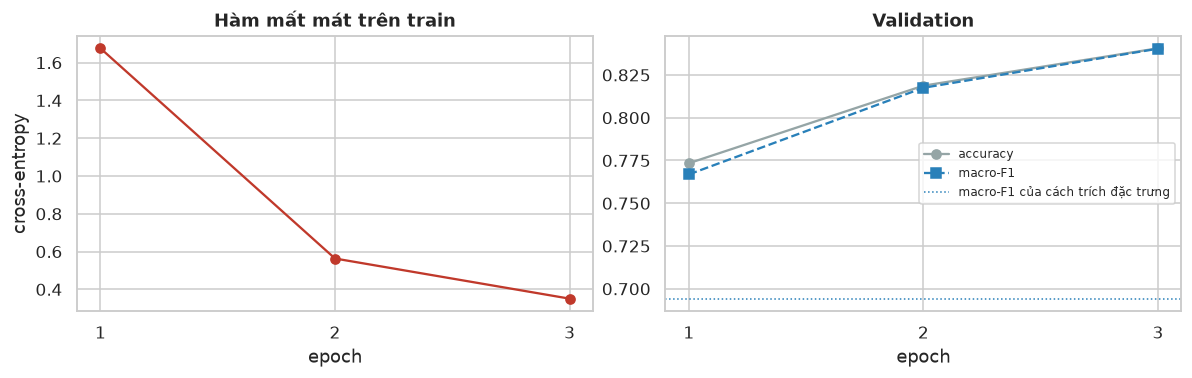

**Hình 7.** Macro-F1 validation qua các epoch: 0.767, 0.817, 0.840; hàm mất mát train giảm từ 1.676 xuống 0.351. Epoch 3 được giữ lại. Kết luận: sau fine-tune, macro-F1 validation là **0.840**, so với 0.694 khi giữ nguyên ResNet50 (mục 6.2).

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(history["epoch"], history["train_loss"], "o-", color="#c0392b")
axes[0].set_title("Hàm mất mát trên train"); axes[0].set_ylabel("cross-entropy")
axes[1].plot(history["epoch"], history["val_acc"], "o-", color="#95a5a6", label="accuracy")
axes[1].plot(history["epoch"], history["val_macro_f1"], "s--", color="#2980b9", label="macro-F1")
axes[1].axhline(VAL["feature_extractor"]["macro_f1"], color="#2980b9", ls=":", lw=1,
                label="macro-F1 của cách trích đặc trưng")
axes[1].set_title("Validation"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_xticks(history["epoch"])
fig.tight_layout()

show_fig(fig, "fig07_finetune_curves",
    f"Macro-F1 validation qua các epoch: {', '.join(f'{v:.3f}' for v in history['val_macro_f1'])}; hàm mất mát train giảm "
    f"từ {history['train_loss'].iloc[0]:.3f} xuống {history['train_loss'].iloc[-1]:.3f}. Epoch {best['epoch']} được giữ "
    f"lại. Kết luận: sau fine-tune, macro-F1 validation là **{best['metrics']['macro_f1']:.3f}**, so với "
    f"{VAL['feature_extractor']['macro_f1']:.3f} khi giữ nguyên ResNet50 (mục 6.2).")

- **Nhận xét:**
  - Fine-tune huấn luyện 15.0 triệu trên 23.6 triệu tham số.
  - Macro-F1 validation tăng qua mỗi epoch (0.767, 0.817, 0.840), epoch 3 tốt nhất, cao hơn cách trích đặc trưng (0.694) 14.6 điểm. Ngay sau epoch 1, mô hình fine-tune đã vượt cách trích đặc trưng.
  - Validation vẫn đang tăng ở epoch 3, nên huấn luyện thêm có thể còn cải thiện; nhóm giữ 3 epoch để notebook chạy nhanh trên Colab.

### 6.4 Baseline: đặc trưng thủ công

Để biết mạng học sẵn đóng góp bao nhiêu, cùng một Logistic Regression được huấn luyện trên đặc trưng thiết kế bằng tay,
không dùng CNN. Mỗi ảnh được thu nhỏ về 128 x 128 px rồi tóm tắt bằng hai đặc trưng thủ công:

- **Histogram màu** trong không gian HSV (OpenCV `cv2.calcHist`, 8 x 8 x 8 = 512 chiều): trên đĩa có những màu nào và
  nhiều đến đâu.
- **SIFT** trên ảnh xám (OpenCV `cv2.SIFT_create`): tìm các điểm nổi bật (góc, mép, chi tiết nhỏ) và mô tả vùng quanh
  mỗi điểm bằng một vector 128 chiều về hướng của các cạnh, tức hình dạng và kết cấu cục bộ của món ăn.

Mỗi ảnh cho ra một số điểm SIFT khác nhau, nên cần thêm bước **túi từ thị giác** (bag of visual words) để có vector cùng
độ dài: `MiniBatchKMeans` của scikit-learn gom các vector SIFT của 2 000 ảnh train thành 256 cụm ("từ thị giác"), rồi
mỗi ảnh được mô tả bằng tỉ lệ điểm SIFT rơi vào từng cụm (256 chiều). Bộ từ điển chỉ học trên train để tránh rò rỉ.
Vector cuối cùng có 512 + 256 = 768 chiều và được chuẩn hóa bằng `StandardScaler` (mục 5.3).

In [27]:
N_WORDS = 256

def small_rgb(path):
    x = np.asarray(Image.open(PROC_DIR / path).convert("RGB"))
    return cv2.resize(x, (128, 128), interpolation=cv2.INTER_AREA)

def sift(x):
    _, desc = cv2.SIFT_create().detectAndCompute(cv2.cvtColor(x, cv2.COLOR_RGB2GRAY), None)
    return desc if desc is not None else np.zeros((0, 128), np.float32)

sample = np.random.default_rng(SEED).choice(TR, size=2000, replace=False)
with ThreadPoolExecutor(max_workers=16) as pool:
    sample_desc = np.vstack(list(pool.map(lambda p: sift(small_rgb(p)), df["path"].values[sample])))
codebook = MiniBatchKMeans(n_clusters=N_WORDS, random_state=SEED).fit(sample_desc)
print(f"Tu dien: {N_WORDS} tu, hoc tu {len(sample_desc):,} vector SIFT cua {len(sample):,} anh train")

def handcrafted(path):
    x = small_rgb(path)
    hsv = cv2.cvtColor(x, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256]).ravel()
    hist /= hist.sum() + 1e-8
    desc = sift(x)
    words = np.bincount(codebook.predict(desc), minlength=N_WORDS) if len(desc) else np.zeros(N_WORDS)
    return np.concatenate([hist, words / max(words.sum(), 1)]).astype(np.float32)

with ThreadPoolExecutor(max_workers=16) as pool:
    hc = list(pool.map(handcrafted, df["path"].values[ALL_OK]))
X_HC = np.zeros((len(df), len(hc[0])), np.float32)
X_HC[ALL_OK] = np.stack(hc)
print("Dac trung thu cong:", X_HC[ALL_OK].shape)

FEATURES["handcrafted"] = X_HC
MODELS["handcrafted"] = make_model("handcrafted").fit(X_HC[TR], y[TR])
VAL["handcrafted"] = metrics(y[VA], MODELS["handcrafted"].predict_proba(X_HC[VA]))
pd.DataFrame([VAL["handcrafted"]], index=["Handcrafted (colour histogram + SIFT) + Logistic Regression"]).round(4)

Tu dien: 256 tu, hoc tu 411,234 vector SIFT cua 2,000 anh train


Dac trung thu cong: (25136, 768)


,acc,macro_f1,top3,top5
Handcrafted (colour histogram + SIFT) + Logistic Regression,0.2529,0.2405,0.4692,0.5813


- **Nhận xét:**
  - Đặc trưng thủ công đạt macro-F1 validation 0.241 và top-3 0.469: cao hơn nhiều so với đoán ngẫu nhiên (0.033), nhưng thấp hơn ResNet50 trích đặc trưng (0.694) gần 3 lần.
  - Đúng như mục 4.3, màu sắc và hình dạng cục bộ không đủ để phân biệt các món có màu và cách bày giống nhau; đặc trưng học từ một triệu ảnh của ImageNet mô tả ảnh tốt hơn hẳn.

### 6.5 So sánh trên validation và chọn mô hình cuối cùng
Mô hình cuối cùng là mô hình có macro-F1 validation cao nhất. Tập test được dùng một lần cho cả ba mô hình ở mục 7, để
so sánh chúng trên cùng một tập test; không chỉnh lại gì sau khi thấy điểm test.

In [28]:
APPROACHES = {
    "handcrafted": "Handcrafted (colour histogram + SIFT) + Logistic Regression",
    "feature_extractor": "ResNet50 frozen + Logistic Regression",
    "finetune": "ResNet50 fine-tune",
}
val_res = pd.DataFrame([{"role": r, "model": name, **VAL[r]} for r, name in APPROACHES.items()])
FINAL = val_res.loc[val_res["macro_f1"].idxmax(), "role"]
display(val_res.round(4))
print("Mo hinh cuoi cung:", APPROACHES[FINAL])

,role,model,acc,macro_f1,top3,top5
0,handcrafted,Handcrafted (colour histogram + SIFT) + Logist...,0.2529,0.2405,0.4692,0.5813
1,feature_extractor,ResNet50 frozen + Logistic Regression,0.6962,0.6942,0.8728,0.9304
2,finetune,ResNet50 fine-tune,0.8406,0.8403,0.9471,0.9753


Mo hinh cuoi cung: ResNet50 fine-tune


## 7. Đánh giá trên tập test

### 7.1 Kết quả trên test và so sánh với bài báo gốc
Mỗi mô hình được đánh giá **một lần** trên tập test. Bài báo gốc báo cáo accuracy 77.54% và top-5 accuracy 96.07%.

In [29]:
TEST_SCORES, rows = {}, []
for role, name in APPROACHES.items():
    S = net_scores(net, TE) if role == "finetune" else MODELS[role].predict_proba(FEATURES[role][TE])
    TEST_SCORES[role] = S
    m = metrics(y[TE], S)
    rows.append({"role": role, "model": name, "final": role == FINAL, "val_macro_f1": VAL[role]["macro_f1"],
                 "test_acc": m["acc"], "test_macro_f1": m["macro_f1"], "test_top3": m["top3"], "test_top5": m["top5"]})
test_res = pd.DataFrame(rows)
display(test_res.round(4))

S_final = TEST_SCORES[FINAL]
pred_final = S_final.argmax(1)

,role,model,final,val_macro_f1,test_acc,test_macro_f1,test_top3,test_top5
0,handcrafted,Handcrafted (colour histogram + SIFT) + Logist...,False,0.2405,0.2522,0.2400,0.4544,0.5683
1,feature_extractor,ResNet50 frozen + Logistic Regression,False,0.6942,0.6952,0.6945,0.8762,0.9306
2,finetune,ResNet50 fine-tune,True,0.8403,0.8363,0.8397,0.9470,0.9738


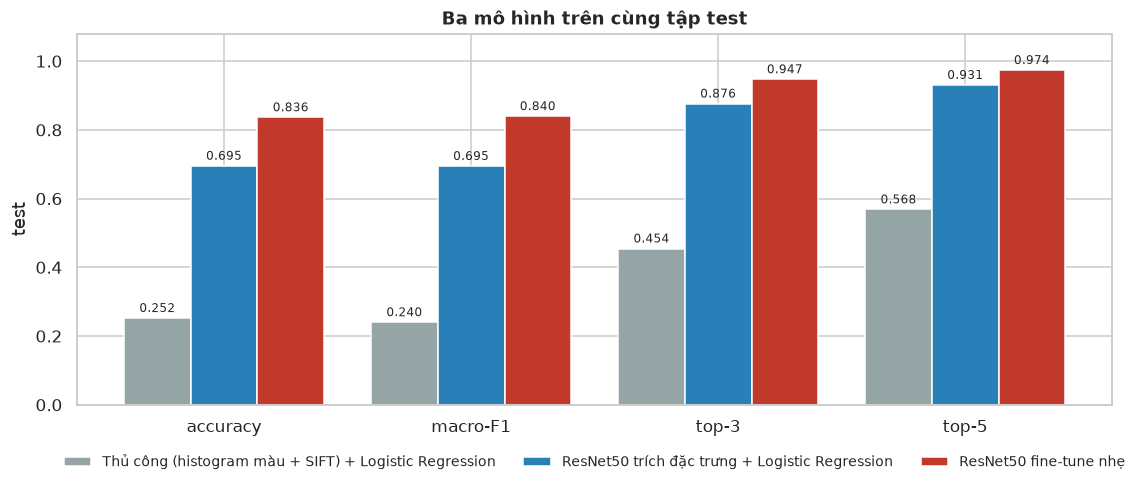

**Hình 8.** Macro-F1 trên test tăng từ 0.240 (đặc trưng thủ công) lên 0.695 (ResNet50 trích đặc trưng, +45.5 điểm) và 0.840 (fine-tune nhẹ, +14.5 điểm so với trích đặc trưng). Cả ba dùng cùng một kiểu đầu phân loại. Kết luận: đặc trưng học sẵn từ ImageNet là bước tiến lớn nhất, và học lại khối cuối cho món ăn Việt Nam còn cải thiện thêm đáng kể.

In [30]:
roles = [("handcrafted", "Thủ công (histogram màu + SIFT) + Logistic Regression", "#95a5a6"),
         ("feature_extractor", "ResNet50 trích đặc trưng + Logistic Regression", "#2980b9"),
         ("finetune", "ResNet50 fine-tune nhẹ", "#c0392b")]
t = test_res.set_index("role")
cols, names = ["test_acc", "test_macro_f1", "test_top3", "test_top5"], ["accuracy", "macro-F1", "top-3", "top-5"]
fig, ax = plt.subplots(figsize=(11, 4.6))
x, w = np.arange(len(cols)), 0.27
for k, (role, label, color) in enumerate(roles):
    bars = ax.bar(x + (k - 1) * w, t.loc[role, cols].astype(float), w, label=label, color=color)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in t.loc[role, cols]], fontsize=8, padding=2)
ax.set_xticks(x, names); ax.set_ylim(0, 1.08); ax.set_ylabel("test")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9, frameon=False)
ax.set_title("Ba mô hình trên cùng tập test")
fig.tight_layout()
f1 = t["test_macro_f1"]
show_fig(fig, "fig08_model_comparison",
    f"Macro-F1 trên test tăng từ {f1['handcrafted']:.3f} (đặc trưng thủ công) lên {f1['feature_extractor']:.3f} (ResNet50 "
    f"trích đặc trưng, +{100 * (f1['feature_extractor'] - f1['handcrafted']):.1f} điểm) và {f1['finetune']:.3f} "
    f"(fine-tune nhẹ, {100 * (f1['finetune'] - f1['feature_extractor']):+.1f} điểm so với trích đặc trưng). Cả ba dùng "
    f"cùng một kiểu đầu phân loại. Kết luận: đặc trưng học sẵn từ ImageNet là bước tiến lớn nhất, và học lại khối cuối "
    f"cho món ăn Việt Nam còn cải thiện thêm đáng kể.")

**Nhận xét.** Mô hình cuối cùng là **ResNet50 fine-tune**. Trên 5 040 ảnh test, mô hình đạt accuracy 0.8363, macro-F1 0.8397, top-3 0.9470 và top-5 0.9738, cao hơn bài báo gốc (accuracy 0.7754, top-5 0.9607). Thứ tự ba mô hình trên test giống trên validation: đặc trưng thủ công (macro-F1 0.2400), ResNet50 trích đặc trưng (0.6945), ResNet50 fine-tune (0.8397). Macro-F1 trên test gần như bằng trên validation (0.8397 so với 0.8403).

### 7.2 Mỗi món được nhận ra tốt đến đâu?
F1 của từng món với mô hình cuối cùng, và ma trận nhầm lẫn chuẩn hóa theo hàng: mỗi hàng là 100% ảnh của một món, ô
ngoài đường chéo cho biết bao nhiêu phần trăm ảnh của món đó bị đoán thành món khác.

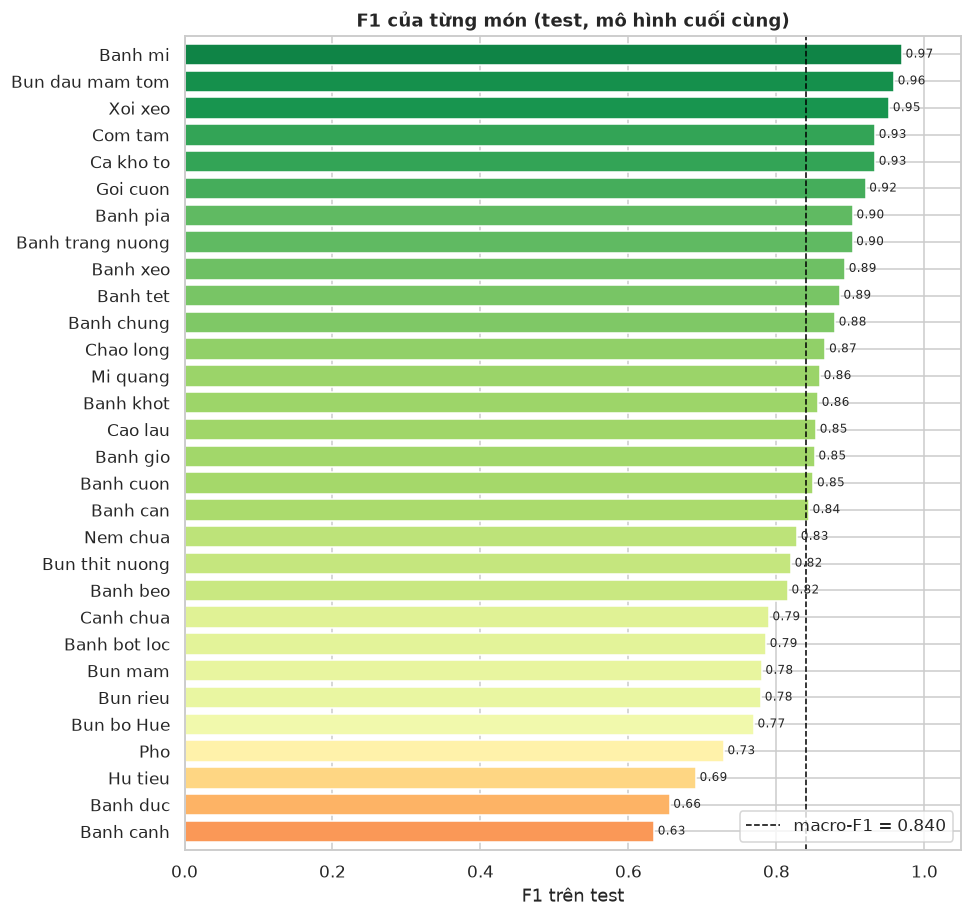

**Hình 9.** Dễ nhất: Banh mi (0.97), Bun dau mam tom (0.96), Xoi xeo (0.95). Khó nhất: Banh canh (0.63), Banh duc (0.66), Hu tieu (0.69). Kết luận: F1 trải từ 0.63 đến 0.97, nên con số trung bình che mất việc một số món bị nhận ra kém hơn hẳn.

In [31]:
n_train = pd.Series(np.bincount(y[TR], minlength=N_CLASSES), index=DISH)
f1_cls = pd.Series(f1_score(y[TE], pred_final, labels=LABELS, average=None), index=DISH).sort_values()
fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(f1_cls.index, f1_cls.values, color=plt.cm.RdYlGn((f1_cls.values - 0.5) / 0.5))
for yy, v in enumerate(f1_cls.values):
    ax.text(v + 0.005, yy, f"{v:.2f}", va="center", fontsize=8)
macro = f1_cls.mean()
ax.axvline(macro, color="black", ls="--", lw=1, label=f"macro-F1 = {macro:.3f}")
ax.set_xlim(0, 1.05); ax.set_xlabel("F1 trên test"); ax.legend(loc="lower right"); ax.margins(y=0.01)
ax.set_title("F1 của từng món (test, mô hình cuối cùng)")
fig.tight_layout()
show_fig(fig, "fig09_per_class_f1",
    "Dễ nhất: " + ", ".join(f"{k} ({v:.2f})" for k, v in f1_cls.iloc[::-1].head(3).items())
    + ". Khó nhất: " + ", ".join(f"{k} ({v:.2f})" for k, v in f1_cls.head(3).items())
    + f". Kết luận: F1 trải từ {f1_cls.min():.2f} đến {f1_cls.max():.2f}, nên con số trung bình che mất việc một số món "
    f"bị nhận ra kém hơn hẳn.")

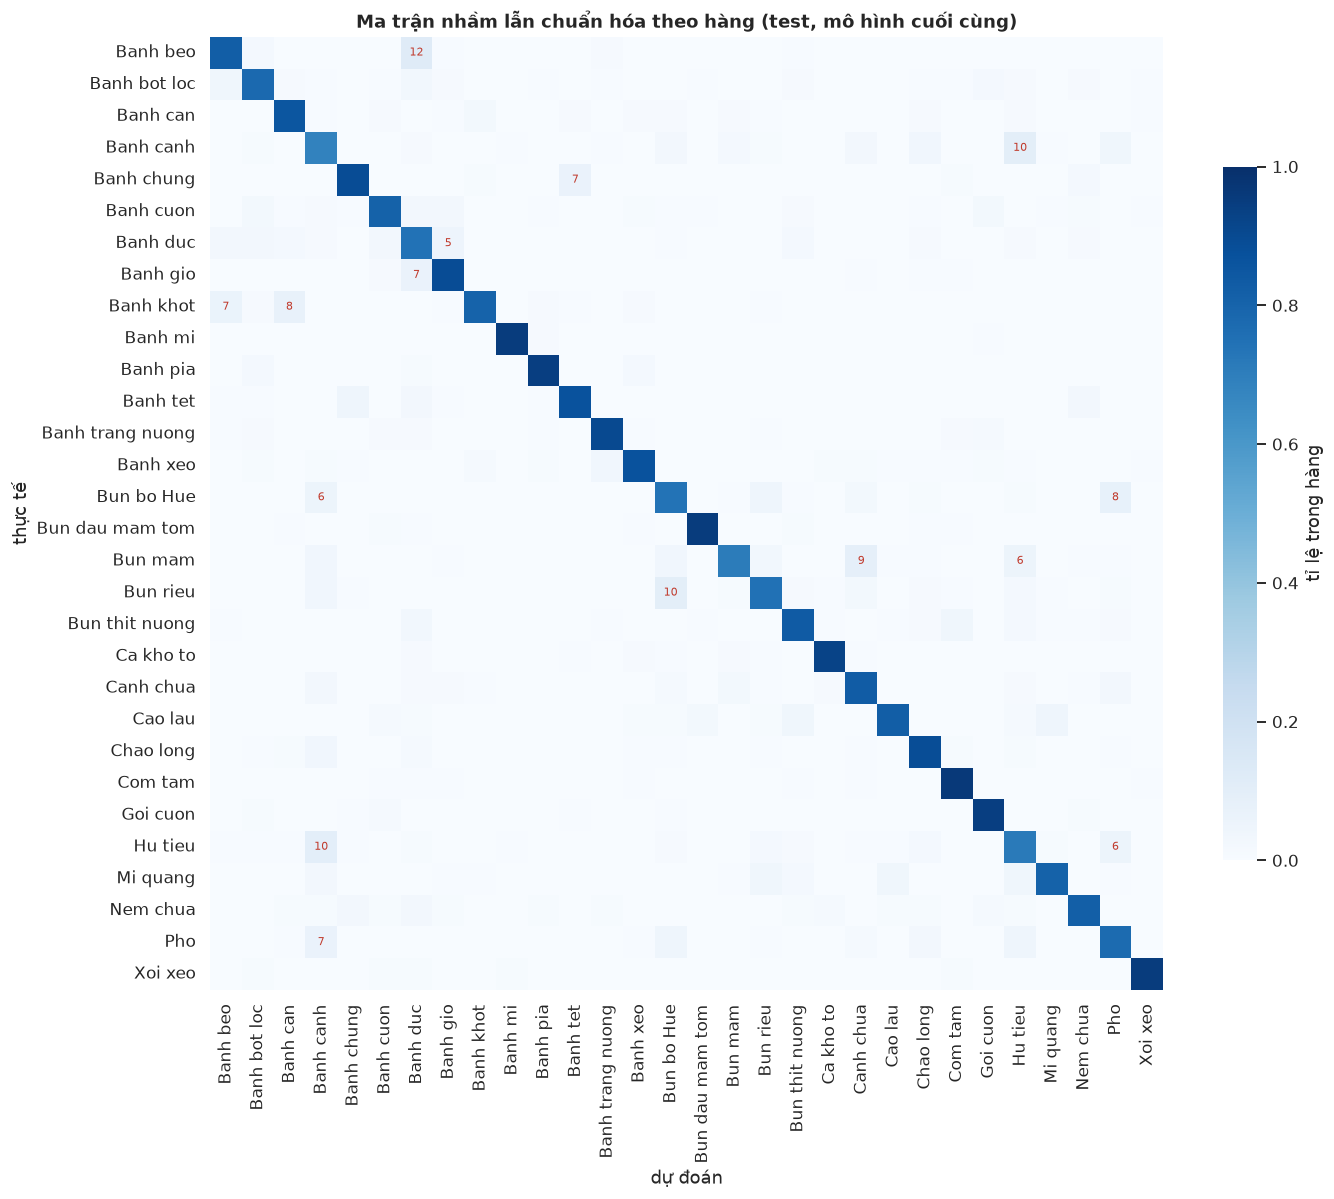

**Hình 10.** Đường chéo chiếm ưu thế (accuracy 83.6%). Số màu đỏ là các ô ngoài đường chéo từ 5% trở lên; có 15 ô như vậy trên 870 ô. Kết luận: lỗi không rải đều mà tập trung vào một số cặp món, được phân tích ở mục 7.3.

In [32]:
cm = confusion_matrix(y[TE], pred_final, labels=LABELS)
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(cmn, cmap="Blues", vmin=0, vmax=1, xticklabels=DISH, yticklabels=DISH, ax=ax, square=True,
            cbar_kws={"shrink": 0.7, "label": "tỉ lệ trong hàng"})
for r in range(N_CLASSES):
    for c in range(N_CLASSES):
        if r != c and cmn[r, c] >= 0.05:
            ax.text(c + 0.5, r + 0.5, f"{100 * cmn[r, c]:.0f}", ha="center", va="center", fontsize=7, color="#c0392b")
ax.set_xlabel("dự đoán"); ax.set_ylabel("thực tế")
ax.set_title("Ma trận nhầm lẫn chuẩn hóa theo hàng (test, mô hình cuối cùng)")
fig.tight_layout()
off = cmn.copy()
np.fill_diagonal(off, 0)
show_fig(fig, "fig10_confusion_matrix",
    f"Đường chéo chiếm ưu thế (accuracy {pct(accuracy_score(y[TE], pred_final))}). Số màu đỏ là các ô ngoài đường chéo "
    f"từ 5% trở lên; có {int((off >= 0.05).sum())} ô như vậy trên {N_CLASSES * (N_CLASSES - 1)} ô. Kết luận: lỗi "
    f"không rải đều mà tập trung vào một số cặp món, được phân tích ở mục 7.3.")

- **Nhận xét:**
  - F1 từng món trải từ 0.63 (Bánh canh) đến 0.97 (Bánh mì).
  - Ba món khó nhất là Bánh canh, Bánh đúc và Hủ tiếu, đều thuộc nhóm món nước hoặc bánh làm từ bột gạo đã thấy ở mục 4.2. Ba món dễ nhất là Bánh mì (0.97), Bún đậu mắm tôm (0.96) và Xôi xéo (0.95).
  - Ma trận nhầm lẫn có 15 ô ngoài đường chéo từ 5% trở lên, trên tổng số 870 ô.

### 7.3 Những món nào hay bị nhầm với nhau?
Năm ô ngoài đường chéo lớn nhất của ma trận nhầm lẫn, kèm chiều ngược lại (món B bị đoán thành món A), và ảnh của các
lỗi đó đặt cạnh một ảnh được đoán đúng của món bị đoán nhầm sang.

,true_dish,predicted_as,share_of_true,n_images,reverse_share
0,Banh beo,Banh duc,0.1240,16,0.0301
1,Bun rieu,Bun bo Hue,0.1039,24,0.0458
2,Banh canh,Hu tieu,0.1036,20,0.1015
3,Hu tieu,Banh canh,0.1015,20,0.1036
4,Bun mam,Canh chua,0.0903,14,0.0242


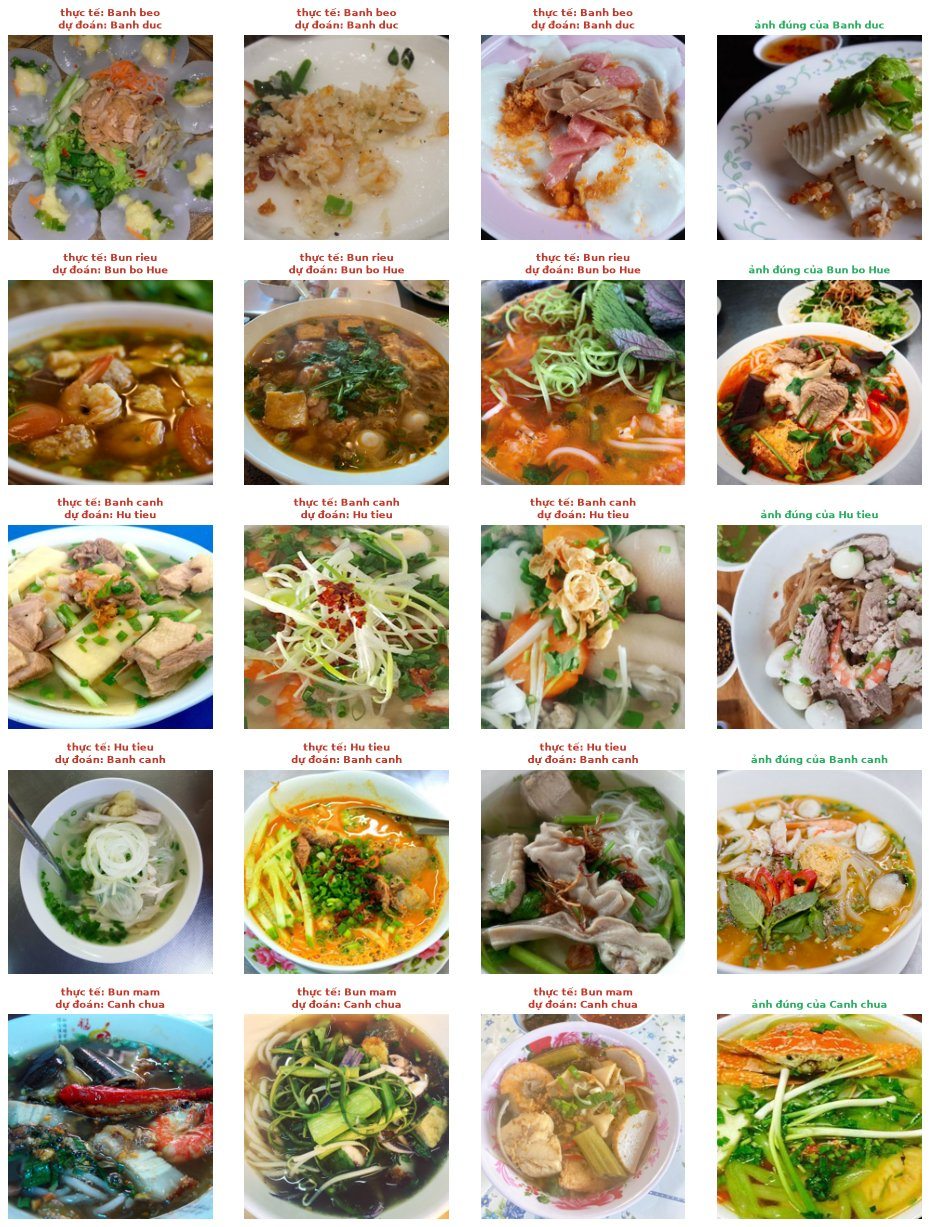

**Hình 11.** Ba lỗi của mỗi cặp nhầm nhiều nhất (đỏ) cạnh một ảnh đoán đúng của món bị đoán nhầm sang (xanh). Cặp nhầm nhiều nhất là **Banh beo -> Banh duc** (12.4% ảnh Banh beo). Năm cặp này chiếm 94 trên 825 lỗi; 4 cặp bị nhầm theo cả hai chiều (chiều ngược lại từ 3% trở lên).

In [33]:
top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:5], off.shape))[0]
CONF_PAIRS = pd.DataFrame([{"true_dish": DISH[r], "predicted_as": DISH[c], "share_of_true": round(off[r, c], 4),
                            "n_images": int(cm[r, c]), "reverse_share": round(off[c, r], 4)} for r, c in top])
display(CONF_PAIRS)

te_true, n_err = y[TE], int((pred_final != y[TE]).sum())
fig, axes = plt.subplots(5, 4, figsize=(12, 15.5))
for row, (r, c) in enumerate(top):
    wrong = TE[(te_true == r) & (pred_final == c)][:3]
    ref = TE[(te_true == c) & (pred_final == c)][:1]
    for col, g in enumerate(list(wrong) + list(ref)):
        ax = axes[row, col]
        ax.imshow(load_rgb(df.at[g, "path"], 220))
        if col < len(wrong):
            ax.set_title(f"thực tế: {DISH[r]}\ndự đoán: {DISH[c]}", fontsize=9, color="#c0392b")
        else:
            ax.set_title(f"ảnh đúng của {DISH[c]}", fontsize=9, color="#27ae60")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
show_fig(fig, "fig11_confused_pairs",
    f"Ba lỗi của mỗi cặp nhầm nhiều nhất (đỏ) cạnh một ảnh đoán đúng của món bị đoán nhầm sang (xanh). Cặp nhầm nhiều "
    f"nhất là **{CONF_PAIRS.iloc[0]['true_dish']} -> {CONF_PAIRS.iloc[0]['predicted_as']}** "
    f"({pct(CONF_PAIRS.iloc[0]['share_of_true'])} ảnh {CONF_PAIRS.iloc[0]['true_dish']}). Năm cặp này chiếm "
    f"{CONF_PAIRS['n_images'].sum()} trên {n_err} lỗi; "
    f"{int((CONF_PAIRS['reverse_share'] >= 0.03).sum())} cặp bị nhầm theo cả hai chiều (chiều ngược lại từ 3% trở lên).",
    photo=True)

- **Nhận xét:**
  - Cặp nhầm nhiều nhất là Bánh bèo -> Bánh đúc (12.4% ảnh bánh bèo, 16 ảnh) và Bún riêu -> Bún bò Huế (10.4%, 24 ảnh).
  - Bánh canh và Hủ tiếu bị nhầm theo cả hai chiều với tỉ lệ gần bằng nhau (10.4% và 10.2%).
  - Năm cặp chiếm 94 trên 825 lỗi (11.4%). Mọi cặp đều là hai món cùng nhóm: bánh làm từ bột gạo (bánh bèo, bánh đúc) hoặc món nước (bún riêu, bún bò Huế, bánh canh, hủ tiếu, bún mắm, canh chua), đúng với những nhóm món giống nhau đã thấy ở mục 4.2.

### 7.4 Mô hình sai ở đâu?
Tỉ lệ đoán sai của mô hình cuối cùng trên tập test được so sánh theo các đặc điểm đo được của ảnh: độ tin cậy của mô
hình (xác suất của món được dự đoán), việc ảnh có bản sao mang nhãn khác trong bộ dữ liệu (`cross_class_dup`, mục
5.1), độ sáng và kích thước ảnh. Sau đó, F1 của từng món được so với số ảnh train của món đó.

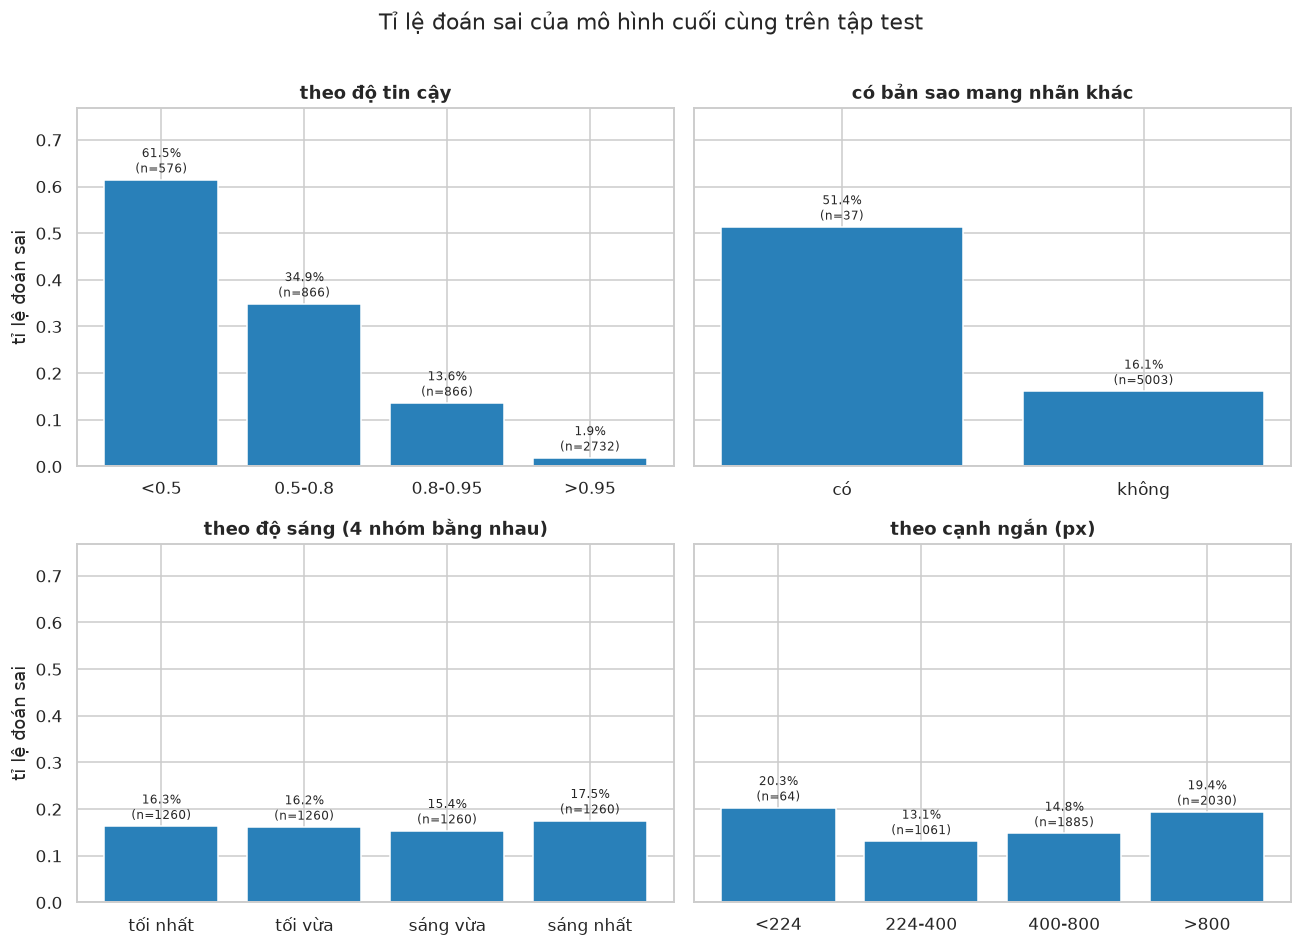

**Hình 12.** Tỉ lệ sai chung là 16.4%. Theo độ tin cậy: 61.5% khi xác suất dưới 0.5 so với 1.9% khi trên 0.95. Ảnh có bản sao mang nhãn khác sai 51.4% so với 16.1%. Theo độ sáng: từ 15.4% đến 17.5%; theo kích thước: từ 13.1% đến 20.3%. Kết luận: độ tin cậy thấp và nhãn mâu thuẫn là hai dấu hiệu rõ nhất của lỗi, còn độ sáng và kích thước ảnh ảnh hưởng ít hơn nhiều.

In [34]:
prob = S_final
err = df.loc[TE, ["path", "folder", "short_side", "brightness", "cross_class_dup"]].reset_index(drop=True)
err["pred"] = [DISH[k] for k in pred_final]
err["confidence"] = prob.max(1)
err["error"] = pred_final != y[TE]
err["confidence_bin"] = pd.cut(err["confidence"], [0, 0.5, 0.8, 0.95, 1], labels=["<0.5", "0.5-0.8", "0.8-0.95", ">0.95"])
err["brightness_bin"] = pd.qcut(err["brightness"], 4, labels=["tối nhất", "tối vừa", "sáng vừa", "sáng nhất"])
err["size_bin"] = pd.cut(err["short_side"], [0, 224, 400, 800, np.inf], labels=["<224", "224-400", "400-800", ">800"])
err["dup_label"] = err["cross_class_dup"].map({True: "có", False: "không"})

panels = [("confidence_bin", "theo độ tin cậy"), ("dup_label", "có bản sao mang nhãn khác"),
          ("brightness_bin", "theo độ sáng (4 nhóm bằng nhau)"), ("size_bin", "theo cạnh ngắn (px)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
RATES = {}
for ax, (col, title) in zip(axes.ravel(), panels):
    g = err.groupby(col, observed=True)["error"].agg(["mean", "size"])
    RATES[col] = g
    bars = ax.bar(g.index.astype(str), g["mean"], color="#2980b9")
    ax.bar_label(bars, labels=[f"{100 * r:.1f}%\n(n={n})" for r, n in zip(g["mean"], g["size"])], fontsize=8, padding=2)
    ax.set_title(title); ax.set_xlabel("")
for ax in axes[:, 0]:
    ax.set_ylabel("tỉ lệ đoán sai")
axes[0, 0].set_ylim(0, max(g["mean"].max() for g in RATES.values()) * 1.25)
fig.suptitle("Tỉ lệ đoán sai của mô hình cuối cùng trên tập test", y=1.01)
fig.tight_layout()

rc, rd, rb, rs = (RATES[c]["mean"] for c in ["confidence_bin", "dup_label", "brightness_bin", "size_bin"])
show_fig(fig, "fig12_error_analysis",
    f"Tỉ lệ sai chung là {pct(err['error'].mean())}. Theo độ tin cậy: {pct(rc.iloc[0])} khi xác suất dưới 0.5 so với "
    f"{pct(rc.iloc[-1])} khi trên 0.95. Ảnh có bản sao mang nhãn khác sai {pct(rd.get('có', np.nan))} so với "
    f"{pct(rd['không'])}. Theo độ sáng: từ {pct(rb.min())} đến {pct(rb.max())}; theo kích thước: từ {pct(rs.min())} đến "
    f"{pct(rs.max())}. Kết luận: độ tin cậy thấp và nhãn mâu thuẫn là hai dấu hiệu rõ nhất của lỗi, còn độ sáng và kích "
    f"thước ảnh ảnh hưởng ít hơn nhiều.")

In [35]:
rho, p_value = spearmanr(n_train[f1_cls.index], f1_cls)
median_size = n_train.median()
small_f1 = f1_cls[n_train[f1_cls.index] < median_size].mean()
large_f1 = f1_cls[n_train[f1_cls.index] >= median_size].mean()
print(f"Spearman giua so anh train va F1 tung mon: {rho:.2f} (p = {p_value:.3f})")
print(f"F1 trung binh: mon co < {median_size:.0f} anh train {small_f1:.3f}, mon co >= {median_size:.0f} anh {large_f1:.3f}")

Spearman giua so anh train va F1 tung mon: -0.08 (p = 0.669)
F1 trung binh: mon co < 548 anh train 0.846, mon co >= 548 anh 0.833


Mười sáu ảnh test bị đoán sai mà mô hình tự tin nhất (xác suất của món dự đoán cao nhất). Khi mô hình rất chắc chắn mà
vẫn sai, cần xem lại chính nhãn của ảnh. `[trùng]` đánh dấu ảnh có bản sao mang nhãn khác trong bộ dữ liệu (mục 5.1).

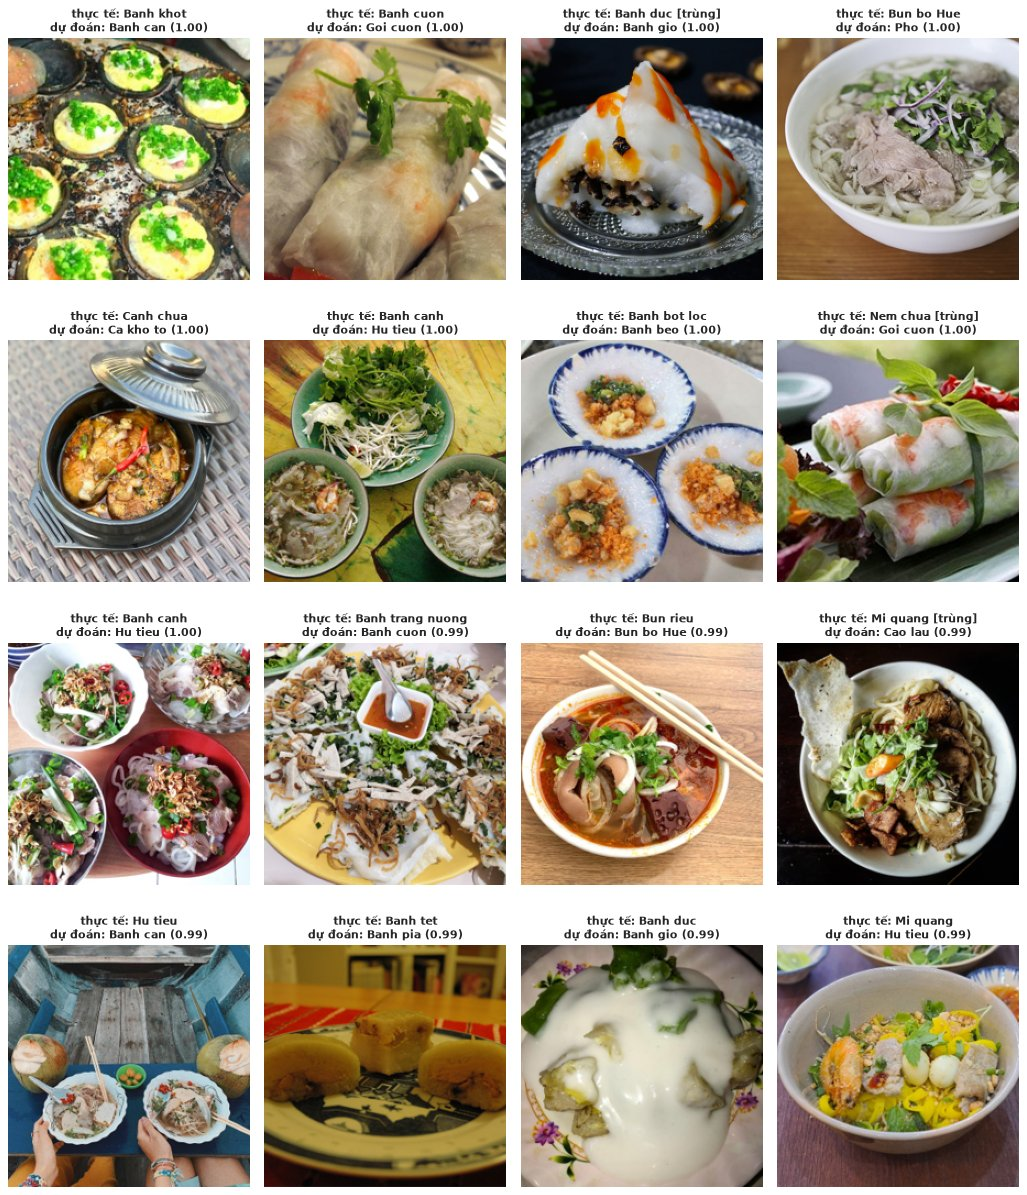

**Hình 13.** Mười sáu lỗi có độ tin cậy cao nhất (từ 1.00 xuống 0.99); 3 ảnh mang dấu `[trùng]`. Độ tin cậy trung vị là 0.54 với ảnh đoán sai và 0.98 với ảnh đoán đúng. Kết luận: nhiều ảnh trong số này trông giống món được dự đoán hơn là nhãn gốc, tức lỗi nằm ở nhãn của dữ liệu chứ không ở mô hình.

In [36]:
worst = err[err["error"]].sort_values("confidence", ascending=False).head(16)
fig, axes = plt.subplots(4, 4, figsize=(13, 15.5))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(load_rgb(r["path"], 220)); ax.axis("off")
    ax.set_title(f"thực tế: {r['folder']}{' [trùng]' if r['cross_class_dup'] else ''}\n"
                 f"dự đoán: {r['pred']} ({r['confidence']:.2f})", fontsize=9.5)
fig.tight_layout()
wrong_conf = err.loc[err["error"], "confidence"]
show_fig(fig, "fig13_confident_errors",
    f"Mười sáu lỗi có độ tin cậy cao nhất (từ {worst['confidence'].max():.2f} xuống {worst['confidence'].min():.2f}); "
    f"{int(worst['cross_class_dup'].sum())} ảnh mang dấu `[trùng]`. Độ tin cậy trung vị là {wrong_conf.median():.2f} với "
    f"ảnh đoán sai và {err.loc[~err['error'], 'confidence'].median():.2f} với ảnh đoán đúng. Kết luận: nhiều ảnh trong "
    f"số này trông giống món được dự đoán hơn là nhãn gốc, tức lỗi nằm ở nhãn của dữ liệu chứ không ở mô hình.",
    photo=True)

- **Nhận xét:**
  - Độ tin cậy là dấu hiệu rõ nhất: ảnh có xác suất dưới 0.5 sai 61.5% (576 ảnh), còn ảnh có xác suất trên 0.95 chỉ sai 1.9% (2 732 ảnh, hơn một nửa tập test).
  - Nhãn mâu thuẫn: 37 ảnh test có bản sao mang nhãn khác bị đoán sai 51.4%, so với 16.1% ở các ảnh còn lại. Với những ảnh này, nhãn trong dữ liệu có thể chính là chỗ sai.
  - Độ sáng gần như không ảnh hưởng (15.4% đến 17.5% giữa bốn nhóm). Theo kích thước, ảnh có cạnh ngắn dưới 224 px sai 20.3% nhưng chỉ có 64 ảnh, còn ảnh trên 800 px cũng sai 19.4%, nên không có xu hướng rõ.
  - Số ảnh train: hệ số tương quan Spearman giữa số ảnh train và F1 của từng món là -0.08 (p = 0.669); món có dưới 548 ảnh train đạt F1 trung bình 0.846, các món còn lại 0.833. Số ảnh không quyết định món nào khó; món khó là món giống một món khác (mục 7.3).
  - **Lỗi tự tin là lỗi của nhãn:** 16 lỗi có độ tin cậy từ 0.99 trở lên (Hình 13). Khi xem từng ảnh, ít nhất 9 trên 16 ảnh khớp với món mô hình dự đoán hơn là nhãn gốc: hai ảnh gắn nhãn Banh cuon và Nem chua là gỏi cuốn, ảnh gắn nhãn Canh chua là cá kho tộ, ảnh gắn nhãn Bun bo Hue là phở, ảnh gắn nhãn Bun rieu là bún bò Huế, ảnh gắn nhãn Banh duc là bánh giò, ảnh gắn nhãn Banh bot loc là bánh bèo, ảnh gắn nhãn Banh khot là bánh căn và ảnh gắn nhãn Banh trang nuong là bánh cuốn. Chỉ 3 trong 16 ảnh có dấu `[trùng]`, nên phần lớn nhãn sai này không tìm được bằng cách tìm ảnh trùng.
- **Quyết định:**
  - Khi xác suất của gợi ý đầu tiên dưới 0.5, ứng dụng nên hiện cả 3 gợi ý thay vì một câu trả lời (mục 8).
  - Nhãn sai trong tập test làm điểm test thấp hơn chất lượng thật của mô hình. Nhóm không sửa nhãn để giữ nguyên tập test chính thức; kiểm tra lại nhãn là hướng mở rộng (mục 9.4).

### 7.5 Lưu bảng kết quả
Toàn bộ bảng test được ghi vào `results/image_metrics.csv` và `results/image_metrics.md`; báo cáo PDF và trang web lấy
số liệu từ các file này.

In [37]:
test_res.round(4).to_csv(RESULTS_DIR / "image_metrics.csv", index=False)

def md_table(d):
    try:
        return d.to_markdown(index=False)
    except ImportError:
        cols = list(d.columns)
        lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
        return "\n".join(lines + ["| " + " | ".join(str(v) for v in r) + " |" for r in d.itertuples(index=False)])

head = test_res[["model", "final", "test_acc", "test_macro_f1", "test_top3", "test_top5"]].round(4)
(RESULTS_DIR / "image_metrics.md").write_text("\n\n".join([
    "# Image (30VNFoods): kết quả trên tập test",
    f"Sinh ra bởi `image.ipynb`. Tập test: {len(TE):,} ảnh. `final = True` là mô hình chọn theo macro-F1 validation.",
    "## Các mô hình", md_table(head),
    "## Làm sạch dữ liệu", md_table(DATA_SUMMARY.reset_index(names="split")),
    "## Các cặp món bị nhầm nhiều nhất", md_table(CONF_PAIRS),
]), encoding="utf-8")
print(f"Da luu {RESULTS_DIR.relative_to(HERE)}/image_metrics.csv va {RESULTS_DIR.relative_to(HERE)}/image_metrics.md")
display(head)

Da luu results/image_metrics.csv va results/image_metrics.md


,model,final,test_acc,test_macro_f1,test_top3,test_top5
0,Handcrafted (colour histogram + SIFT) + Logist...,False,0.2522,0.2400,0.4544,0.5683
1,ResNet50 frozen + Logistic Regression,False,0.6952,0.6945,0.8762,0.9306
2,ResNet50 fine-tune,True,0.8363,0.8397,0.9470,0.9738


## 8. Dự đoán ảnh mới

### 8.1 Hàm dự đoán từ một file ảnh
`predict_image()` chạy toàn bộ quy trình trên một file ảnh bất kỳ: đọc ảnh, đổi sang RGB, cùng phép biến đổi ở mục 5.3,
rồi mô hình cuối cùng, và trả về 3 món có xác suất cao nhất. Trên Colab có thể tải ảnh của mình lên rồi truyền đường dẫn
vào hàm này.

In [38]:
def predict_image(path, k=3):
    x = eval_tf(ImageOps.exif_transpose(Image.open(path)).convert("RGB")).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        if FINAL == "finetune":
            net.eval()
            p = torch.softmax(net(x).float(), 1)[0].cpu().numpy()
        else:
            p = MODELS["feature_extractor"].predict_proba(backbone(x).float().cpu().numpy())[0]
    top = np.argsort(-p)[:k]
    return pd.DataFrame({"dish": [DISH[c] for c in top], "probability": p[top].round(3)})

predict_image(DATA_DIR / df.loc[TE[0], "path"])

,dish,probability
0,Banh beo,0.991
1,Banh bot loc,0.006
2,Chao long,0.001


### 8.2 Thử với ảnh gốc độ phân giải đầy đủ
Sáu ảnh test được chọn ngẫu nhiên, gồm bốn ảnh mô hình đoán đúng và hai ảnh đoán sai ở mục 7, và được đọc từ file gốc
(không phải bản trong `data/processed/`), giống như khi người dùng gửi ảnh chụp từ điện thoại.

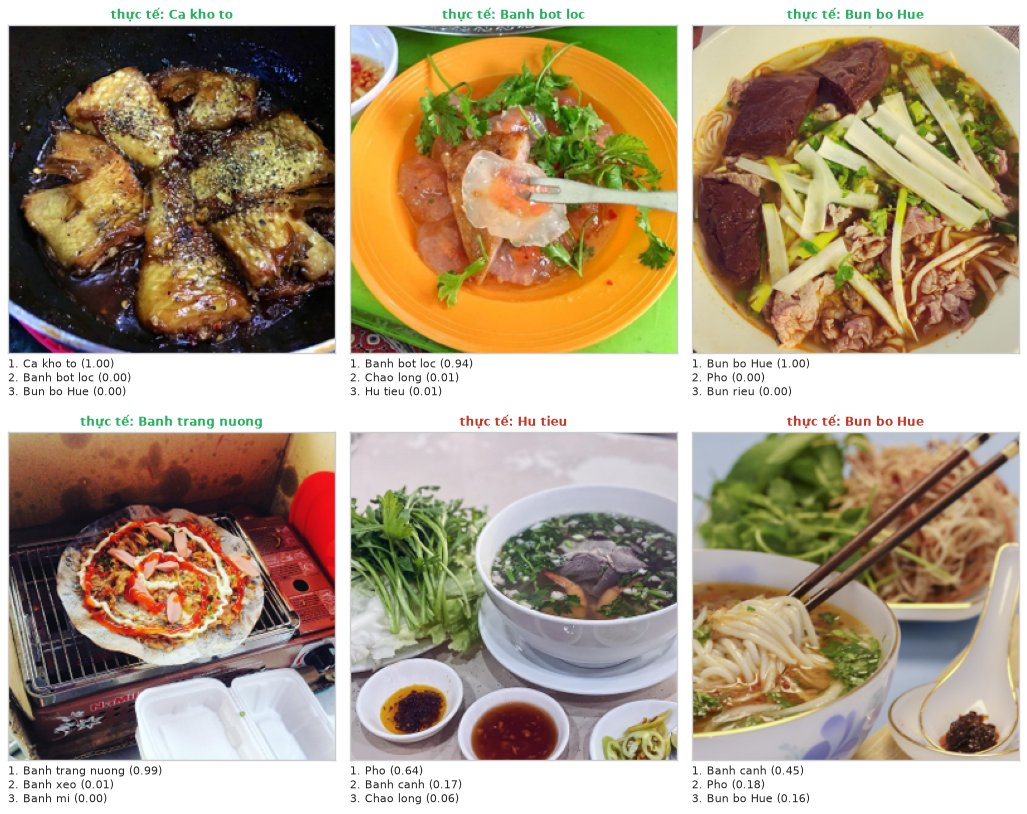

**Hình 14.** Ba gợi ý của mô hình cho sáu ảnh test đọc từ file gốc (tên màu xanh: gợi ý đầu tiên đúng, đỏ: sai), kèm xác suất. Món đúng nằm trong ba gợi ý ở 5 trên 6 ảnh. Kết luận: hàm dự đoán xử lý được ảnh gốc với kích thước bất kỳ nhờ dùng chung phép biến đổi ở mục 5.3, và danh sách ba gợi ý giúp người dùng chọn lại khi gợi ý đầu tiên sai.

In [39]:
rng = np.random.default_rng(SEED + 1)
correct_te = pred_final == y[TE]
demo = np.r_[rng.choice(TE[correct_te], size=4, replace=False), rng.choice(TE[~correct_te], size=2, replace=False)]
fig, axes = plt.subplots(2, 3, figsize=(13, 10.5))
n_top3 = 0
for ax, g in zip(axes.ravel(), demo):
    top3 = predict_image(DATA_DIR / df.at[g, "path"])
    correct = top3["dish"].iloc[0] == df.at[g, "folder"]
    n_top3 += df.at[g, "folder"] in set(top3["dish"])
    ax.imshow(load_rgb(df.at[g, "path"], 260)); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"thực tế: {df.at[g, 'folder']}", fontsize=11, color="#27ae60" if correct else "#c0392b")
    ax.set_xlabel("\n".join(f"{k + 1}. {r.dish} ({r.probability:.2f})" for k, r in enumerate(top3.itertuples())),
                  fontsize=10, loc="left")
fig.tight_layout()
show_fig(fig, "fig14_predictions",
    f"Ba gợi ý của mô hình cho sáu ảnh test đọc từ file gốc (tên màu xanh: gợi ý đầu tiên đúng, đỏ: sai), kèm xác suất. "
    f"Món đúng nằm trong ba gợi ý ở {n_top3} trên 6 ảnh. Kết luận: hàm dự đoán xử lý được ảnh gốc với kích thước bất kỳ "
    f"nhờ dùng chung phép biến đổi ở mục 5.3, và danh sách ba gợi ý giúp người dùng chọn lại khi gợi ý đầu tiên sai.",
    photo=True)

## 9. Kết luận

### 9.1 Tóm tắt kết quả trên tập test

Cả ba mô hình dùng cùng một kiểu đầu phân loại (tuyến tính + softmax), chỉ khác nhau ở đặc trưng.

| Mô hình | Đặc trưng | Accuracy | Macro-F1 | Top-3 | Top-5 |
|---|---|---:|---:|---:|---:|
| Baseline thủ công + Logistic Regression | histogram màu + SIFT (OpenCV) | 0.2522 | 0.2400 | 0.4544 | 0.5683 |
| ResNet50 trích đặc trưng + Logistic Regression | ResNet50 giữ nguyên | 0.6952 | 0.6945 | 0.8762 | 0.9306 |
| **ResNet50 fine-tune nhẹ** (mô hình cuối cùng) | ResNet50, `layer4` học lại | **0.8363** | **0.8397** | **0.9470** | **0.9738** |
| Bài báo gốc | | 0.7754 | | | 0.9607 |

### 9.2 Các câu hỏi đã được trả lời

| # | Câu hỏi | Trả lời (số liệu trên test) |
|---|---|---|
| 1 | Dữ liệu sạch đến đâu? | Không có file lỗi, chỉ 9 ảnh dưới 128 px, nhưng có 403 cặp ảnh trùng: 65 cặp khác nhãn, 186 cặp nối train với val/test. Train bỏ 366 ảnh (mục 3, 5.1). |
| 2 | Đặc trưng CNN huấn luyện sẵn tốt hơn đặc trưng thủ công bao nhiêu? | Với cùng đầu phân loại, macro-F1 tăng từ 0.2400 (histogram màu + SIFT) lên 0.6945 (ResNet50 giữ nguyên), +45.5 điểm (mục 6.4, 7.1). |
| 3 | Trích đặc trưng hay fine-tune nhẹ? | Fine-tune nhẹ: macro-F1 tăng từ 0.6945 lên 0.8397 (+14.5 điểm), top-3 từ 0.8762 lên 0.9470 (mục 6.3, 7.1). |
| 4 | Món nào bị nhầm với nhau? | Các cặp cùng nhóm: bánh bèo -> bánh đúc (12.4%), bún riêu -> bún bò Huế (10.4%), bánh canh và hủ tiếu (cả hai chiều) (mục 7.3). |
| 5 | Mô hình sai ở đâu? | Ảnh có xác suất dưới 0.5 sai 61.5%, trên 0.95 chỉ sai 1.9%; ảnh có bản sao khác nhãn sai 51.4% so với 16.1%. Ít nhất 9 trong 16 lỗi tự tin nhất là ảnh bị gán nhãn sai (mục 7.4). |

### 9.3 Hạn chế

* **Một nhãn cho mỗi ảnh**, trong khi một số ảnh có nhiều món; các biến thể vùng miền của một món được gộp chung một lớp.
* **Nhãn sai vẫn còn trong val và test:** 37 ảnh test có bản sao mang nhãn khác, và ít nhất 9 trong 16 lỗi tự tin nhất là ảnh bị gán nhãn sai. Nhóm chỉ đánh dấu, không sửa nhãn, nên điểm test có thể thấp hơn chất lượng thật của mô hình.
* **pHash chỉ tìm được bản sao của cùng một ảnh**, không tìm được hai ảnh khác nhau chụp cùng một đĩa.
* **Tham số mặc định:** Logistic Regression dùng tham số mặc định của scikit-learn; fine-tune chỉ chạy 3 epoch trong khi validation vẫn đang tăng.
* **Chỉ một mạng pretrained** (ResNet50) được thử; chưa so sánh với các mạng khác.
* **Phạm vi dữ liệu:** ảnh lấy từ Internet thường được chụp đẹp, khác ảnh người dùng chụp bằng điện thoại trong quán ăn, nên độ chính xác thực tế có thể thấp hơn.

### 9.4 Hướng mở rộng

Một số hướng chưa được thực hiện trong notebook này:

* Fine-tune lâu hơn hoặc mở thêm `layer3`; thử các mạng khác, như MobileNetV3 nhẹ hơn để chạy trên điện thoại hoặc ViT-B/16.
* Kiểm tra lại nhãn của các ảnh mô hình đoán sai với độ tin cậy cao và các ảnh có bản sao khác nhãn, rồi sửa hoặc bỏ chúng; tìm ảnh gần trùng bằng độ tương đồng cosine của đặc trưng CNN, ngoài pHash.
* Dùng ngưỡng độ tin cậy trong ứng dụng: hiện một câu trả lời khi mô hình chắc chắn, ngược lại hiện 3 gợi ý.